# Sub-unit hazard from nested reports, with unit offsets

Notebook 06 recovers a smooth spatial field from events reported at ADM2, ADM1 or ADM0. Hazard can also step at administrative borders, through land use, building and drainage that follow jurisdictions. This notebook adds an offset for every unit at every level, each centered on its parent's, and fits them with partial pooling: a unit with few or coarse reports is pulled toward its parent, and a well-reported unit keeps its own value. The questions are how well each resolution of report recovers the offsets, and whether the record can tell a smooth field from a pattern of unit steps. The event count and the mix of reporting levels are calibrated to the global EM-DAT record, so the answer holds at the density the real model will see.

The likelihood is the one from 05 and 06. If an event's reporting level does not depend on where inside its country it fell, the events reported at unit $A$ are a Poisson process thinned to $A$, and

$$\log L = \sum_{A} n_A \log \Lambda_A - \sum_i \lambda_i, \qquad \Lambda_A = \sum_{i \in A} \lambda_i,$$

where $i$ runs over the atoms of the lattice and $A$ over every unit at every level. The reporting probabilities factor out as constants.

In [36]:
from pathlib import Path

import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pymc as pm
import pytensor
import shapely

from nested_plotting import (
    LATTICE_EXTENT,
    POSTERIOR_COLOR,
    RATE_FLOOR,
    TRUTH_COLOR,
    draw_borders,
    draw_stack,
    floored_log10,
    plot_atoms,
    plot_fields,
    spread_over_units,
)

from climate_risk.data.gadm import GADM_LAYER, gadm_path
from climate_risk.data.geo_disasters import load_event_locations
from climate_risk.data_functions.emdat_processing import load_emdat_events
from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()

# One generator per stage, so rerunning a stage never moves the draws of another.
SEED = 20261020
GEOGRAPHY_SEED, COLOR_SEED, FIELD_SEED, EVENT_SEED, REPORTING_SEED, OFFSET_SEED = (SEED + step for step in range(6))

## The geography

The lattice and units of 05 and 06: a square lattice of atoms, grouped into ADM2 units, ADM2 into ADM1 and ADM1 into ADM0. Each level is a partition of the one below it, so an atom has exactly one ancestor at every level.

In [2]:
GRID_SIDE = 30
N_ADM2, N_ADM1, N_ADM0 = 60, 12, 3
LLOYD_STEPS = 25
LEVELS = ("ADM2", "ADM1", "ADM0")

n_atoms = GRID_SIDE**2
column, row = (index.ravel() for index in np.meshgrid(np.arange(GRID_SIDE), np.arange(GRID_SIDE)))
atom_x, atom_y = (column + 0.5) / GRID_SIDE, (row + 0.5) / GRID_SIDE
atom_centroids = np.column_stack([atom_x, atom_y])

# Edges as k / GRID_SIDE, computed once per grid line, so neighbors share them exactly and a
# dissolve leaves no slivers between atoms.
edges = np.arange(GRID_SIDE + 1) / GRID_SIDE
atom_cells = gpd.GeoSeries(shapely.box(edges[column], edges[row], edges[column + 1], edges[row + 1]))

In [3]:
def group_into(centroids, n_groups, *, weights, rng):
    """Assign each child to one of ``n_groups`` compact parents, by weighted Lloyd iteration."""
    seeds = centroids[rng.choice(len(centroids), size=n_groups, replace=False)]
    for _ in range(LLOYD_STEPS):
        parent = np.argmin(((centroids[:, None, :] - seeds[None, :, :]) ** 2).sum(axis=-1), axis=1)
        seeds = np.array(
            [np.average(centroids[parent == group], axis=0, weights=weights[parent == group]) for group in range(n_groups)]
        )

    return parent, seeds


geography_rng = np.random.default_rng(GEOGRAPHY_SEED)
adm2_of_atom, adm2_centroids = group_into(atom_centroids,
                                          N_ADM2,
                                          weights=np.ones(n_atoms),
                                          rng=geography_rng)
adm1_of_adm2, adm1_centroids = group_into(adm2_centroids,
                                          N_ADM1,
                                          weights=np.bincount(adm2_of_atom),
                                          rng=geography_rng)
adm0_of_adm1, _ = group_into(adm1_centroids,
                             N_ADM0,
                             weights=np.bincount(adm1_of_adm2[adm2_of_atom]),
                             rng=geography_rng)

unit_of_atom = {
    "ADM2": adm2_of_atom,
    "ADM1": adm1_of_adm2[adm2_of_atom],
    "ADM0": adm0_of_adm1[adm1_of_adm2[adm2_of_atom]],
}
borders = {
    level: gpd.GeoDataFrame({"unit": unit_of_atom[level]}, geometry=atom_cells).dissolve(by="unit").boundary
    for level in LEVELS
}
atoms_per_unit = {level: np.bincount(unit_of_atom[level]) for level in LEVELS}

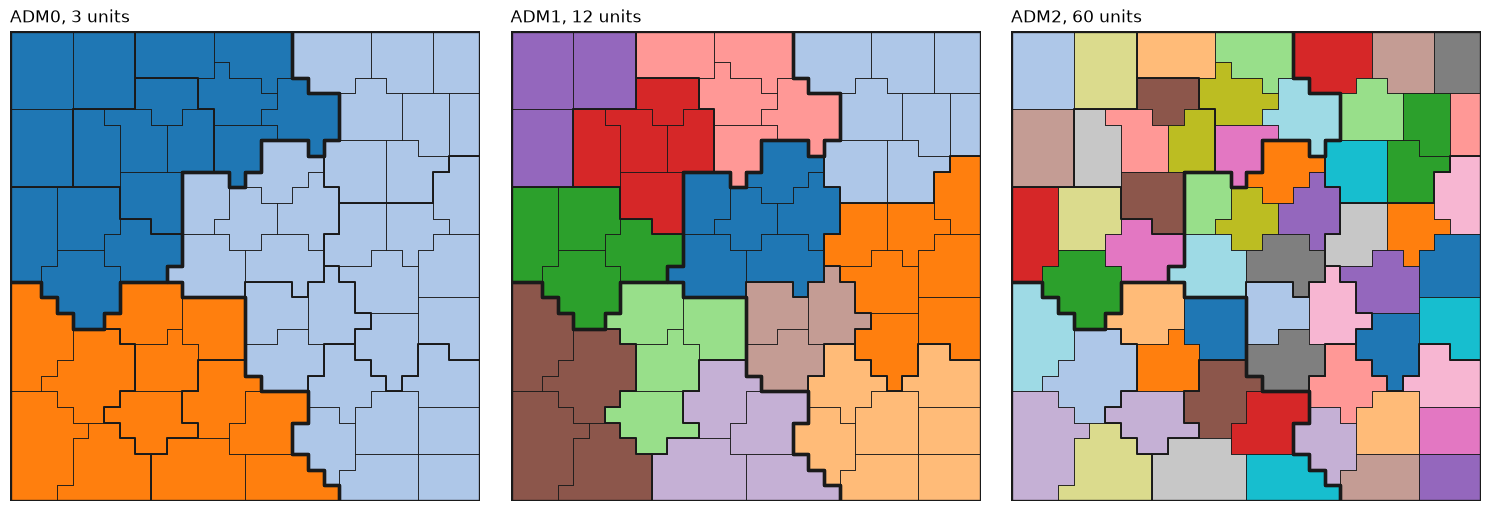

In [4]:
color_rng = np.random.default_rng(COLOR_SEED)

figure, axes = plt.subplots(1, len(LEVELS), figsize=(15, 5))

for axis, level in zip(axes, reversed(LEVELS), strict=True):
    count = len(atoms_per_unit[level])
    palette = plt.get_cmap("tab20")(color_rng.permutation(count) % 20)
    axis.imshow(palette[unit_of_atom[level]].reshape(GRID_SIDE, GRID_SIDE, 4),
                origin="lower",
                extent=LATTICE_EXTENT)
    draw_borders(axis, borders, color="0.1")

    axis.set_axis_off()
    axis.set_title(f"{level}, {count} units", loc="left")

plt.show()

## The real record

The simulation is calibrated to the record the model will see. Geo-Disasters (Teber et al. 2025, [doi:10.5281/zenodo.15487667](https://doi.org/10.5281/zenodo.15487667)) geocodes EM-DAT's climate-related disasters from 1990 to 2023 to GAUL units, one row per ADM1 or ADM2 unit an event touched. An event's report is its units at the finest level it names, so an event reported in six districts counts once in each. Climate-related EM-DAT events that never geocoded are reported only at ADM0. Units held come from GADM, so per-unit figures mix two boundary sets and are approximate, and the 41 countries GADM does not divide at ADM2 drop out of the ADM2 ratios.

In [5]:
DATA_DIR = Path("../../data").resolve()
FIRST_YEAR, LAST_YEAR = 1990, 2023
REAL_LEVELS = (1, 2)
UNIT_KEYS = {1: ["ISO", "ADM1_NAME"], 2: ["ISO", "ADM1_NAME", "ADM2_NAME"]}

locations = pl.from_pandas(load_event_locations(DATA_DIR))

# An event's reporting level is the finest level it names, and only its units at that level are its report.
finest = locations.group_by("DisNo.").agg(pl.col("admin_level").max().alias("finest_level"))
reports = locations.join(finest, on="DisNo.").filter(pl.col("admin_level") == pl.col("finest_level"))

climate_events = (
    load_emdat_events(DATA_DIR)
    .filter(pl.col("disaster_class").is_not_null())
    .with_columns(pl.col("DisNo.").str.slice(0, 4).cast(pl.Int32).alias("year"))
    .filter(pl.col("year").is_between(FIRST_YEAR, LAST_YEAR))
)

gadm_ids = pl.from_pandas(
    pd.DataFrame(gpd.read_file(gadm_path(DATA_DIR),
                               layer=GADM_LAYER,
                               columns=["GID_0", "GID_1", "GID_2"],
                               ignore_geometry=True))
)
units_held = gadm_ids.group_by("GID_0").agg(
    pl.col(f"GID_{level}").filter(pl.col(f"GID_{level}") != "").n_unique().alias(f"ADM{level} units")
    for level in REAL_LEVELS
).rename({"GID_0": "ISO"})

In [6]:
level_counts = [
    reports.filter(pl.col("admin_level") == level)
    .group_by("ISO")
    .agg(pl.len().alias(f"ADM{level} reports"), pl.struct(UNIT_KEYS[level]).n_unique().alias(f"ADM{level} units named"))
    for level in REAL_LEVELS
]
units_per_event = (
    reports.group_by("ISO", "DisNo.").len().group_by("ISO").agg(pl.col("len").median().alias("units named per event"))
)
geocoded = reports.group_by("ISO").agg(pl.col("DisNo.").n_unique().alias("geocoded events"))

country_density = climate_events.group_by("ISO").len("EM-DAT events")
for frame in [geocoded, *level_counts, units_per_event, units_held]:
    country_density = country_density.join(frame, on="ISO", how="left")

country_density = (
    country_density.fill_null(0)
    .with_columns(
        (1 - pl.col("geocoded events") / pl.col("EM-DAT events")).clip(lower_bound=0).alias("share never geocoded"),
        *(
            (pl.col(f"ADM{level} reports") / pl.col(f"ADM{level} units")).alias(f"ADM{level} reports per unit")
            for level in REAL_LEVELS
        ),
        *(
            (pl.col(f"ADM{level} units named") / pl.col(f"ADM{level} units")).alias(f"ADM{level} share of units named")
            for level in REAL_LEVELS
        ),
    )
    .to_pandas()
    .set_index("ISO")
    .replace(np.inf, np.nan)
)

# Countries with at least one climate-related event and at least one ADM1 unit, so the ratios exist.
recorded = country_density[(country_density["EM-DAT events"] > 0) & (country_density["ADM1 units"] > 0)]

print(f"{len(recorded)} countries, {int(recorded['EM-DAT events'].sum())} climate-related EM-DAT events")

208 countries, 10341 climate-related EM-DAT events


In [7]:
QUANTILES = (0.1, 0.25, 0.5, 0.75, 0.9)
SUMMARY_COLUMNS = [
    "EM-DAT events",
    "share never geocoded",
    "ADM1 units",
    "ADM1 reports per unit",
    "ADM1 share of units named",
    "ADM2 units",
    "ADM2 reports per unit",
    "ADM2 share of units named",
    "units named per event",
]

real_summary = recorded[SUMMARY_COLUMNS].quantile(QUANTILES).T
real_summary.columns = [f"{quantile:.0%} of countries" for quantile in QUANTILES]
real_summary.rename_axis(f"across {len(recorded)} countries, {FIRST_YEAR} to {LAST_YEAR}").round(2)

,10% of countries,25% of countries,50% of countries,75% of countries,90% of countries
"across 208 countries, 1990 to 2023",,,,,
EM-DAT events,4.00,8.75,25.00,54.00,92.20
share never geocoded,0.00,0.04,0.12,0.29,0.51
ADM1 units,4.00,7.00,13.00,21.00,32.00
ADM1 reports per unit,0.23,1.00,3.29,7.43,13.17
ADM1 share of units named,0.10,0.50,0.93,1.00,1.00
ADM2 units,0.00,16.00,62.00,187.50,386.90
ADM2 reports per unit,0.00,0.05,0.26,0.87,1.89
ADM2 share of units named,0.00,0.04,0.17,0.46,0.80
units named per event,1.00,1.00,2.00,4.00,5.00


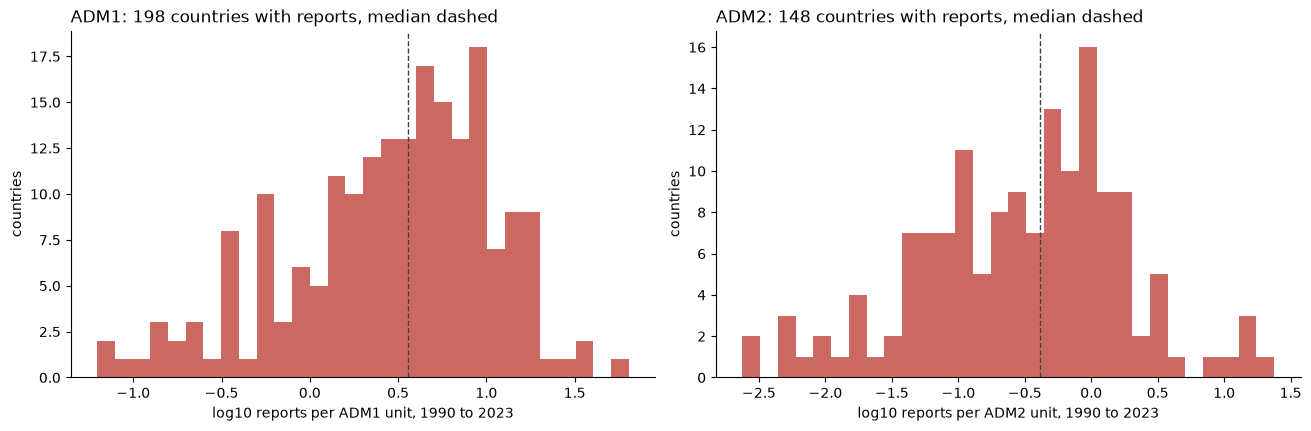

In [8]:
figure, axes = plt.subplots(1, len(REAL_LEVELS), figsize=(13, 4.2))

for axis, level in zip(axes, REAL_LEVELS, strict=True):
    per_unit = recorded[f"ADM{level} reports per unit"].replace(0.0, np.nan).dropna()
    axis.hist(np.log10(per_unit), bins=30, color=POSTERIOR_COLOR, alpha=0.8)
    axis.axvline(np.log10(per_unit.median()),
                 color=TRUTH_COLOR,
                 linestyle="--",
                 linewidth=1.0)
    axis.set_xlabel(f"log10 reports per ADM{level} unit, {FIRST_YEAR} to {LAST_YEAR}")
    axis.set_ylabel("countries")
    axis.set_title(f"ADM{level}: {len(per_unit)} countries with reports, median dashed", loc="left")

plt.show()

In [9]:
event_levels = climate_events.select("DisNo.").unique().join(finest, on="DisNo.", how="left")
n_climate_events = len(event_levels)

REAL_EVENTS_PER_COUNTRY = float(recorded["EM-DAT events"].median())
REAL_LEVEL_SHARES = {
    "ADM2": event_levels.filter(pl.col("finest_level") == 2).height / n_climate_events,
    "ADM1": event_levels.filter(pl.col("finest_level") == 1).height / n_climate_events,
    "ADM0": event_levels.filter(pl.col("finest_level").is_null()).height / n_climate_events,
}

pd.Series({"events per country, median": REAL_EVENTS_PER_COUNTRY,
           **{f"share of events reported at {level}": share for level, share in REAL_LEVEL_SHARES.items()}},
          name="calibration").to_frame().round(3)

,calibration
"events per country, median",25.00
share of events reported at ADM2,0.43
share of events reported at ADM1,0.44
share of events reported at ADM0,0.12


Across 208 countries, the median country holds 25 climate-related events from 1990 to 2023, 13 ADM1 units and 62 ADM2 units. That comes to 3.3 reports per ADM1 unit and 0.26 per ADM2 unit, and 83% of its ADM2 units were never named. Pooled, 43% of events geocode to ADM2, 44% to ADM1, and 12% never geocode. The simulation takes the median country's 25 events for each of its three countries and the pooled shares for its mixed regime. Pooled across countries the units are many, 208 countries and about 3,500 ADM1 units, so the level sds a global model estimates have far more units behind them than the three countries and twelve ADM1 units simulated here.

## The truth

The truth of 06, a log rate linear in distance to river and elevation plus a Matern 3/2 field with a lengthscale near the size of an ADM2 unit, with an offset added for every unit. Each country's offset has sd 0.5, each ADM1 deviates from its country with sd 0.4, and each ADM2 deviates from its ADM1 with sd 0.3, so an atom carries the sum of its three ancestors' offsets. The offsets come from their own generator, so the covariates and the field are those of 06. The intercept is solved so each of the three countries carries the median real country's 25 events. The share of each term's variance that lies inside units at each level is the part a report at that level cannot see.

In [10]:
TARGET_EVENTS = round(N_ADM0 * REAL_EVENTS_PER_COUNTRY)
TRUE_SLOPES = np.array([-0.8, 0.5])
COVARIATE_NAMES = ("distance to river", "elevation")
TRUE_FIELD_AMPLITUDE = 0.7
TRUE_FIELD_LENGTHSCALE = 0.12
TRUE_OFFSET_SDS = {"ADM2": 0.3, "ADM1": 0.4, "ADM0": 0.5}
FIELD_JITTER = 1e-8


def standardized(values):
    """Centered and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


def matern32(points, *, amplitude, lengthscale):
    """The Matern 3/2 covariance between every pair of ``points``."""
    scaled = np.sqrt(3.0) * np.sqrt(((points[:, None, :] - points[None, :, :]) ** 2).sum(axis=-1)) / lengthscale

    return amplitude**2 * (1.0 + scaled) * np.exp(-scaled)


river_x = 0.5 + 0.2 * np.sin(2.5 * np.pi * atom_y)
elevation = np.sin(3.0 * atom_x + 1.0) * np.cos(2.0 * atom_y) + 0.6 * atom_y
covariates = np.column_stack([standardized(np.abs(atom_x - river_x)), standardized(elevation)])

field_rng = np.random.default_rng(FIELD_SEED)
field_covariance = matern32(atom_centroids, amplitude=TRUE_FIELD_AMPLITUDE, lengthscale=TRUE_FIELD_LENGTHSCALE)
field_covariance[np.diag_indices(n_atoms)] += FIELD_JITTER
true_field = np.linalg.cholesky(field_covariance) @ field_rng.standard_normal(n_atoms)
true_field -= true_field.mean()

offset_rng = np.random.default_rng(OFFSET_SEED)
true_offsets = {
    level: offset_rng.normal(loc=0.0, scale=TRUE_OFFSET_SDS[level], size=len(atoms_per_unit[level])) for level in LEVELS
}
offset_part = sum(true_offsets[level][unit_of_atom[level]] for level in LEVELS)

linear_part = covariates @ TRUE_SLOPES
TRUE_INTERCEPT = float(np.log(TARGET_EVENTS) - np.log(np.exp(linear_part + true_field + offset_part).sum()))
true_log_rate = TRUE_INTERCEPT + linear_part + true_field + offset_part
true_rate = np.exp(true_log_rate)

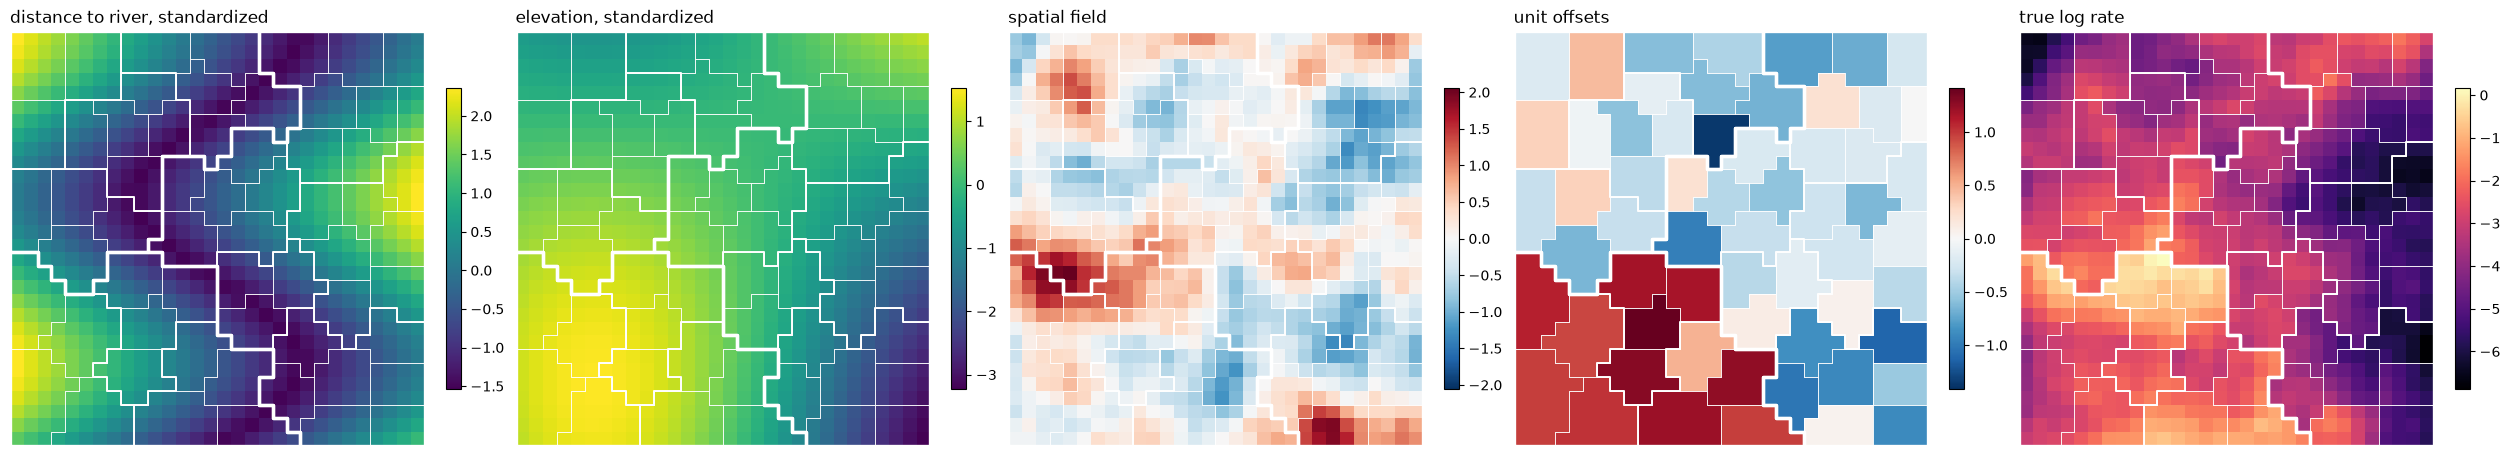

In [11]:
components = {
    **dict(zip(COVARIATE_NAMES, covariates.T, strict=True)),
    "spatial field": true_field,
    "unit offsets": offset_part - offset_part.mean(),
}
DIVERGING = ("spatial field", "unit offsets")

figure, axes = plt.subplots(1, len(components) + 1, figsize=(5.0 * (len(components) + 1), 4.6))

for axis, (name, values) in zip(axes, components.items()):
    limit = np.abs(values).max()
    drawn = plot_atoms(axis,
                       values,
                       borders,
                       title=name if name in DIVERGING else f"{name}, standardized",
                       cmap="RdBu_r" if name in DIVERGING else "viridis",
                       vmin=-limit if name in DIVERGING else None,
                       vmax=limit if name in DIVERGING else None)
    figure.colorbar(drawn, ax=axis, shrink=0.7)

drawn = plot_atoms(axes[-1], true_log_rate, borders, title="true log rate")
figure.colorbar(drawn, ax=axes[-1], shrink=0.7)

plt.show()

In [12]:
def within_share(values, units):
    """Share of the variance of ``values`` that lies inside units, invisible to a report at that level."""
    unit_means = np.bincount(units, weights=values) / np.bincount(units)

    return float(((values - unit_means[units]) ** 2).sum() / ((values - values.mean()) ** 2).sum())


pd.DataFrame(
    {
        level: {name: within_share(values, unit_of_atom[level]) for name, values in components.items()}
        for level in LEVELS
    }
).rename_axis("variance inside units").round(3)

,ADM2,ADM1,ADM0
variance inside units,,,
distance to river,0.10,0.44,0.96
elevation,0.03,0.17,0.57
spatial field,0.34,0.84,0.96
unit offsets,0.00,0.15,0.25


The offsets are constant inside their own units, so none of their variance lies inside ADM2 units, 15% lies inside ADM1 units and 25% inside the countries. Three quarters of it is the step between countries: the draw gave the countries a spread of 0.60, against 0.23 for the ADM1 deviations and 0.32 for the ADM2 deviations. Every report, even at ADM0, sees the country step. Only reports at ADM2 or finer see the ADM2 steps.

## Events and how they are reported

The six regimes of 05 and 06. Events are drawn once, at the atoms, and each regime reports the same events differently: the oracle at the atom, every event at ADM2, ADM1 or ADM0, a mixture, and a per-country habit where one country reports mostly at ADM2, one mostly at ADM1 and one only as a whole country. The mixture uses the real record's shares: 43% of climate-related events geocode to ADM2, 44% to ADM1, and 12% never geocode and stand at ADM0. In every regime the level is drawn independently of where inside its country the event fell, which is the condition under which the thinned likelihood is exact. Real events also name several units each, a median of two, which the simulation does not.

In [13]:
ALL_LEVELS = ("atom", *LEVELS)

unit_of_atom["atom"] = np.arange(n_atoms)
n_units = {level: int(unit_of_atom[level].max()) + 1 for level in ALL_LEVELS}
first_row = dict(zip(ALL_LEVELS, np.cumsum([0, *(n_units[level] for level in ALL_LEVELS[:-1])]), strict=True))
rows_of = {level: slice(first_row[level], first_row[level] + n_units[level]) for level in ALL_LEVELS}

reporting = Aggregation(units=tuple(f"{level} {unit}" for level in ALL_LEVELS for unit in range(n_units[level])),
                        rows=np.concatenate([first_row[level] + unit_of_atom[level] for level in ALL_LEVELS]),
                        columns=np.tile(np.arange(n_atoms), len(ALL_LEVELS)),
                        weights=np.ones(n_atoms * len(ALL_LEVELS)),
                        n_cells=n_atoms)


def country_of_units(level):
    """The ADM0 each unit at ``level`` lies in."""
    countries = np.empty(n_units[level], dtype=int)
    countries[unit_of_atom[level]] = unit_of_atom["ADM0"]

    return countries


country_of_row = np.concatenate([country_of_units(level) for level in ALL_LEVELS])
level_of_row = np.repeat(np.arange(len(ALL_LEVELS)), [n_units[level] for level in ALL_LEVELS])


def reports_by_country(counts):
    """Events reported at each level in each country, shape ``(country, level)``."""
    table = np.zeros((N_ADM0, len(ALL_LEVELS)))
    np.add.at(table, (country_of_row, level_of_row), counts)

    return table

In [14]:
MIXED_SHARES = REAL_LEVEL_SHARES
COUNTRY_SHARES = ({"ADM2": 0.8, "ADM1": 0.2}, {"ADM1": 0.8, "ADM0": 0.2}, {"ADM0": 1.0})


def record(atoms, levels):
    """The count reported at each row of ``reporting``, given each event's atom and reporting level."""
    reported_rows = [first_row[level] + unit_of_atom[level][atom] for atom, level in zip(atoms, levels, strict=True)]

    return np.bincount(reported_rows, minlength=reporting.n_units)


def country_level(country, rng):
    """One reporting level drawn from ``country``'s own shares."""
    shares = COUNTRY_SHARES[country]

    return rng.choice(list(shares), p=list(shares.values()))


def draw_regimes(atoms, rng):
    """Every regime's record of the events at ``atoms``, with reporting levels drawn from ``rng``."""
    regimes = {level: record(atoms, [level] * len(atoms)) for level in ALL_LEVELS}
    regimes["mixed"] = record(atoms,
                              rng.choice(list(MIXED_SHARES),
                                         size=len(atoms),
                                         p=list(MIXED_SHARES.values())))
    regimes["by country"] = record(atoms, [country_level(country, rng) for country in unit_of_atom["ADM0"][atoms]])

    return regimes


event_atoms = np.repeat(np.arange(n_atoms), np.random.default_rng(EVENT_SEED).poisson(true_rate))
n_events = len(event_atoms)
regimes = draw_regimes(event_atoms, np.random.default_rng(REPORTING_SEED))

pd.DataFrame(
    {regime: {level: counts[rows_of[level]].sum() for level in ALL_LEVELS} for regime, counts in regimes.items()}
).rename_axis("events reported at")

,atom,ADM2,ADM1,ADM0,mixed,by country
events reported at,,,,,,
atom,79,0,0,0,0,0
ADM2,0,79,0,0,28,44
ADM1,0,0,79,0,38,17
ADM0,0,0,0,79,13,18


In [15]:
pd.DataFrame(reports_by_country(regimes["by country"]).astype(int),
             index=pd.Index([f"ADM0 {country}" for country in range(N_ADM0)], name="by country"),
             columns=ALL_LEVELS)

,atom,ADM2,ADM1,ADM0
by country,,,,
ADM0 0,0,44,9,0
ADM0 1,0,0,8,2
ADM0 2,0,0,0,16


In [16]:
DENSITY_LEVELS = ("ADM1", "ADM2")


def simulated_per_unit(counts, level):
    """Reports per unit at ``level`` in one simulated record, the real record's density measure."""
    return counts[rows_of[level]].sum() / n_units[level]


simulated = {
    f"simulated, {regime}": {f"{level} reports per unit": simulated_per_unit(regimes[regime], level) for level in DENSITY_LEVELS}
    for regime in ("ADM2", "ADM1", "mixed", "by country")
}
real = {
    f"real, {quantile:.0%} of countries": {
        f"{level} reports per unit": recorded[f"{level} reports per unit"].quantile(quantile) for level in DENSITY_LEVELS
    }
    for quantile in (0.5, 0.75, 0.9)
}

pd.DataFrame(simulated | real).round(2)

,"simulated, ADM2","simulated, ADM1","simulated, mixed","simulated, by country","real, 50% of countries","real, 75% of countries","real, 90% of countries"
ADM1 reports per unit,0.00,6.58,3.17,1.42,3.29,7.43,13.17
ADM2 reports per unit,1.32,0.00,0.47,0.73,0.26,0.87,1.89


The mixed regime is the realistic one. Its 3.2 reports per ADM1 unit match the median country (3.3), and its 0.47 per ADM2 unit sit between the median (0.26) and the 75th percentile (0.87). The single-level regimes are denser than most of the world at their own level, since they put every event there. The simulation still names one unit per event, where real events name a median of two.

The offsets reshape the record. ADM0 0 drew an offset of +0.63 against -0.68 and -0.59 for the other two countries, so it holds 53 of the 79 events. In the per-country record that country reports mostly at ADM2 (44 events), and the ADM0-only country contributes a total of 16.

## The model, fitted under each regime

The model of 06 with the offsets added in the truth's form. Each level's offsets are drawn around zero with a learned sd, and an atom's rate carries the sum of its country's offset, its ADM1's deviation and its ADM2's deviation. A unit's offset moves away from its parent's only as far as its own reports pull it, which is the partial pooling. Offsets are non-centered: each is its level's sd times a standard normal.

The field and the offsets overlap. A smooth field can mimic a pattern of unit offsets, and the offset sds can trade against the field amplitude, so the fits show whether the record separates them. The likelihood is unchanged: every row of the operator is a Poisson count at its country's observed share for its level times the unit's rate, which leaves the rate's likelihood exact up to a constant.

The field's Hilbert-space basis is sized against the lengthscale prior, whose central 95% runs from 0.06 to 0.65. The boundary factor $c$ sets the longest lengthscale the basis can carry and the number of basis functions $m$ per axis the shortest. PyMC's `approx_hsgp_hyperparams` sizes both for one dimension and asks for 179 functions per axis, 32,041 in two, more than the lattice has atoms. The sizing here is checked directly instead: the approximate covariance against the exact Matern 3/2 on the lattice's own atoms.

In [17]:
HSGP_BOUNDARY_FACTOR = 4.0
HSGP_BASIS_PER_AXIS = 50
CHECKED_LENGTHSCALES = (0.06, 0.12, 0.3, 0.6, 1.2)


def hsgp_covariance_error(m, c, lengthscale):
    """Relative Frobenius error of the HSGP covariance against the exact Matern 3/2 on the lattice's atoms."""
    gp = pm.gp.HSGP(m=[m, m], c=c, cov_func=pm.gp.cov.Matern32(input_dim=2, ls=lengthscale))
    basis, sqrt_spectral_density = pytensor.function([], list(gp.prior_linearized(X=atom_centroids)))()
    approximate = (basis * sqrt_spectral_density**2) @ basis.T
    exact = matern32(atom_centroids, amplitude=1.0, lengthscale=lengthscale)

    return float(np.linalg.norm(approximate - exact) / np.linalg.norm(exact))


pd.DataFrame(
    {
        f"m={m}, c={c}": {lengthscale: hsgp_covariance_error(m, c, lengthscale) for lengthscale in CHECKED_LENGTHSCALES}
        for m, c in ((26, 1.5), (HSGP_BASIS_PER_AXIS, HSGP_BOUNDARY_FACTOR))
    }
).rename_axis("lengthscale").round(3)

,"m=26, c=1.5","m=50, c=4.0"
lengthscale,,
0.06,0.04,0.09
0.12,0.00,0.01
0.30,0.13,0.00
0.60,0.50,0.00
1.20,0.87,0.11


The basis of 06 keeps the error at 4% or below for lengthscales 0.06 and 0.12 but reaches 13% at 0.3 and 50% at 0.6, so it cannot represent the long half of the prior. The larger basis holds the error at 1% or below from 0.12 to 0.6 and gives up some accuracy at both tails, 9% at 0.06 and 11% at 1.2. The truth's lengthscale of 0.12 is accurate under both.

In [18]:
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "target_accept": 0.9,
    "nuts_sampler": "nutpie",
    "random_seed": SEED,
}
OFFSET_SD_PRIOR = 0.5


def build_model(counts):
    """Log-linear rate plus a latent field and nested unit offsets, every unit at every level observed as a Poisson count."""
    coords = {
        "covariate": COVARIATE_NAMES,
        "atom": np.arange(n_atoms),
        "row": reporting.units,
        **{level: np.arange(n_units[level]) for level in LEVELS},
    }

    by_country = reports_by_country(counts)
    observed_shares = by_country / by_country.sum(axis=1, keepdims=True)

    with pm.Model(coords=coords) as model:
        intercept = pm.Normal("intercept",
                              mu=0.0,
                              sigma=2.0)
        slopes = pm.Normal("slopes",
                           mu=0.0,
                           sigma=1.0,
                           dims="covariate")

        # Mode at 0.1 of the domain, about the side of an ADM2 unit, with a tail out past an ADM0.
        field_lengthscale = pm.InverseGamma("field_lengthscale",
                                            alpha=3.0,
                                            beta=0.4)
        field_amplitude = pm.HalfNormal("field_amplitude", sigma=1.0)
        gp = pm.gp.HSGP(m=[HSGP_BASIS_PER_AXIS, HSGP_BASIS_PER_AXIS],
                        c=HSGP_BOUNDARY_FACTOR,
                        cov_func=field_amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=field_lengthscale))
        field = gp.prior("field", X=atom_centroids, dims="atom")

        # Summing every level's offsets at the atom nests them: an ADM2's total is its ADM1's plus its own deviation.
        offset_part = 0.0
        for level in LEVELS:
            offset_sd = pm.HalfNormal(f"{level}_offset_sd", sigma=OFFSET_SD_PRIOR)
            standard = pm.Normal(f"{level}_offset_standard",
                                 mu=0.0,
                                 sigma=1.0,
                                 dims=level)
            offsets = pm.Deterministic(f"{level}_offset", offset_sd * standard, dims=level)
            offset_part = offset_part + offsets[unit_of_atom[level]]

        log_rate = pm.Deterministic("log_rate",
                                    intercept + pm.math.dot(covariates, slopes) + field + offset_part,
                                    dims="atom")

        unit_rate = reporting.aggregate_symbolic(pm.math.exp(log_rate))
        pm.Poisson("events",
                   mu=observed_shares[country_of_row, level_of_row] * unit_rate,
                   observed=counts,
                   dims="row")

    return model

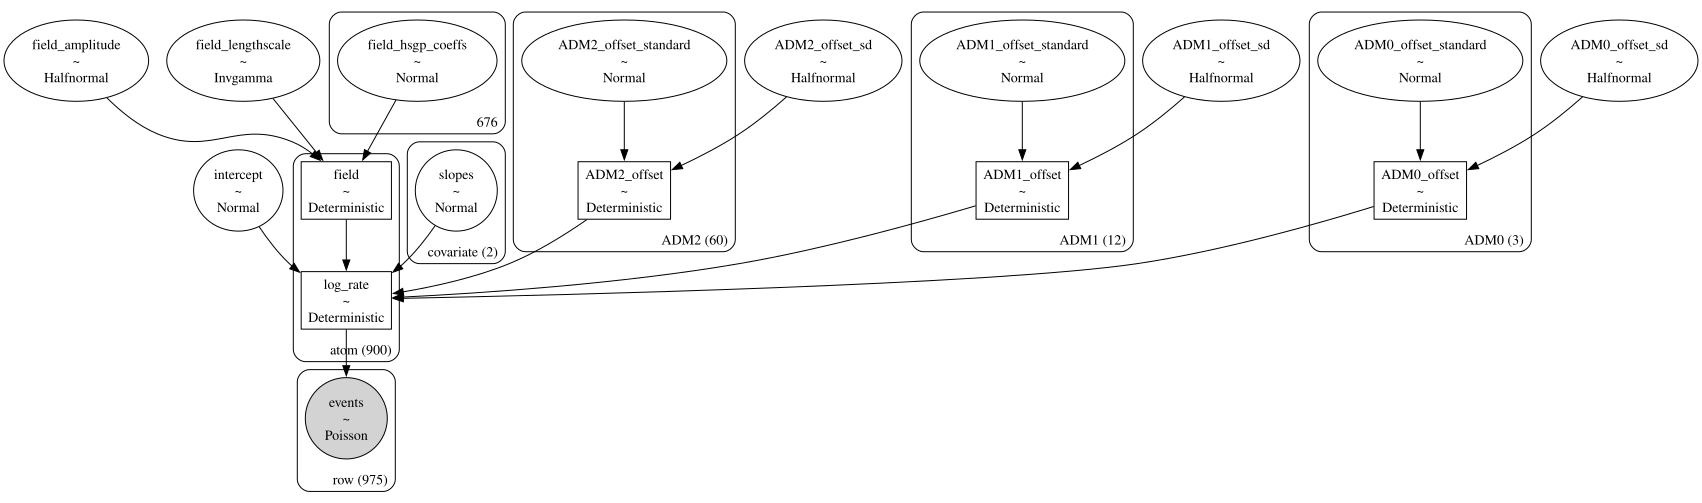

In [22]:
build_model(counts).to_graphviz()

In [19]:
fits = {}
for regime, counts in regimes.items():
    with build_model(counts):
        fits[regime] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


...

Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

## What each regime recovers

The slopes, the field's hyperparameters and the three offset sds against their true values, then the recovery of the field, the offsets and every atom's log rate.

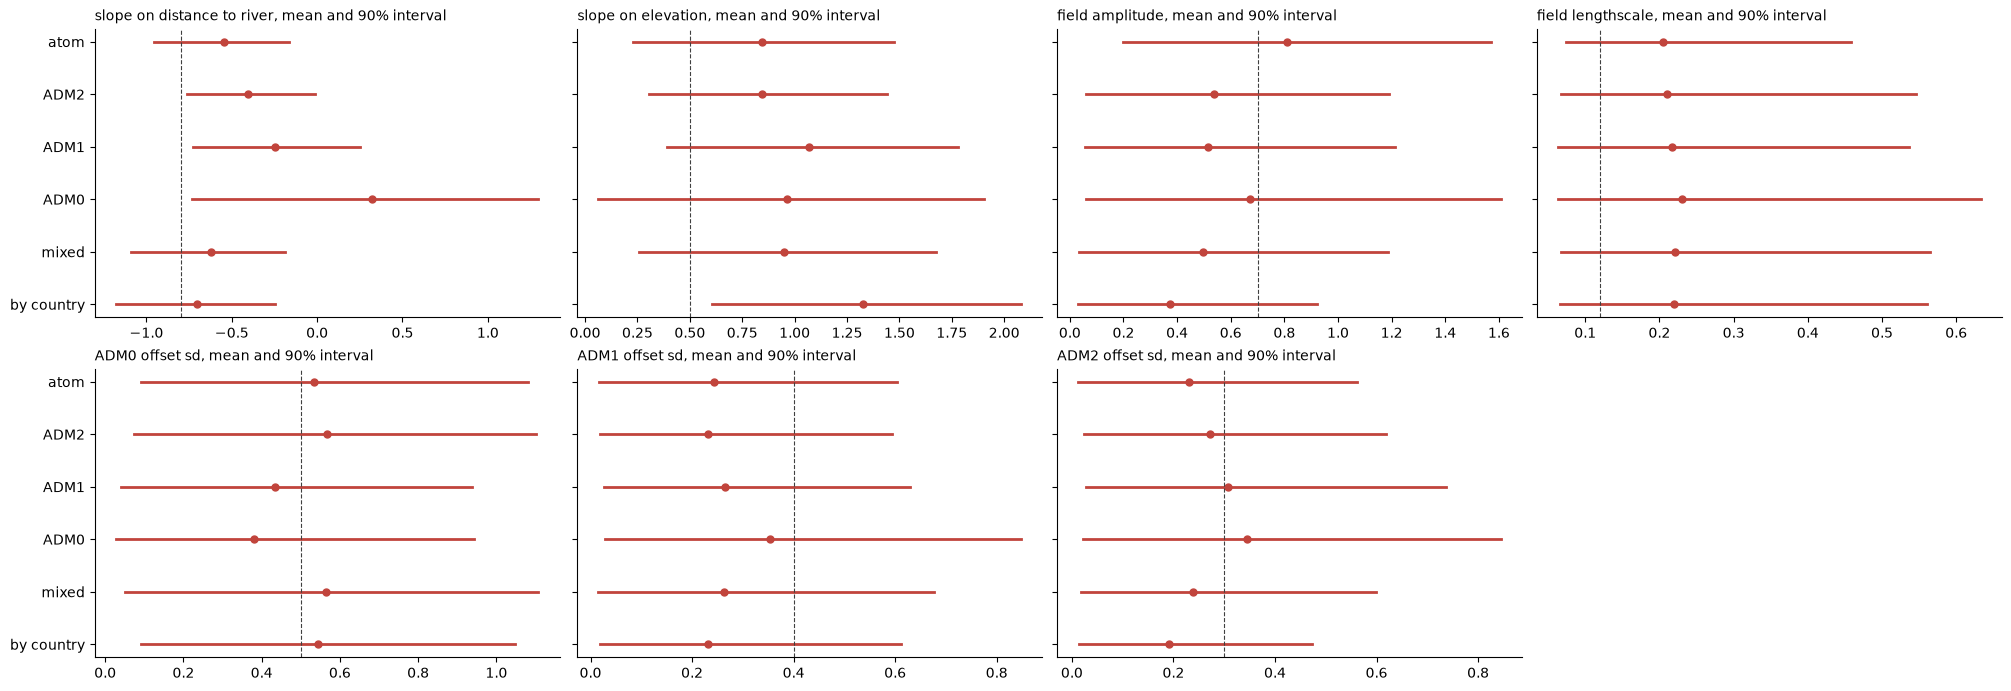

In [20]:
INTERVAL = 0.9
INTERVAL_BOUNDS = ((1 - INTERVAL) / 2, (1 + INTERVAL) / 2)

TRUE_PARAMETERS = {
    **{f"slope on {name}": slope for name, slope in zip(COVARIATE_NAMES, TRUE_SLOPES, strict=True)},
    "field amplitude": TRUE_FIELD_AMPLITUDE,
    "field lengthscale": TRUE_FIELD_LENGTHSCALE,
    **{f"{level} offset sd": TRUE_OFFSET_SDS[level] for level in reversed(LEVELS)},
}


def parameter_draws(posterior):
    """Draws of every parameter with a known true value, keyed as in ``TRUE_PARAMETERS``."""
    return {
        **{f"slope on {name}": posterior["slopes"].sel(covariate=name) for name in COVARIATE_NAMES},
        "field amplitude": posterior["field_amplitude"],
        "field lengthscale": posterior["field_lengthscale"],
        **{f"{level} offset sd": posterior[f"{level}_offset_sd"] for level in reversed(LEVELS)},
    }


figure, axes = plt.subplots(2, 4, figsize=(20, 6.8), sharey=True)

for axis, (name, truth) in zip(axes.ravel(), TRUE_PARAMETERS.items()):
    for position, idata in enumerate(fits.values()):
        draws = parameter_draws(idata.posterior)[name]
        lower, upper = draws.quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
        axis.plot([lower, upper],
                  [position, position],
                  color=POSTERIOR_COLOR,
                  linewidth=2.0)
        axis.plot(float(draws.mean()),
                  position,
                  "o",
                  color=POSTERIOR_COLOR,
                  markersize=5)
    axis.axvline(truth,
                 color=TRUTH_COLOR,
                 linestyle="--",
                 linewidth=0.8)
    axis.set_title(f"{name}, mean and {INTERVAL:.0%} interval", loc="left", fontsize=10)

axes.ravel()[-1].remove()
for row in axes:
    row[0].set_yticks(range(len(fits)), list(fits))
axes[0, 0].invert_yaxis()
plt.show()

No record identifies the three offset sds. Their posterior means run from 0.19 to 0.57 and their 90% intervals from about 0.02 to 1.1, close to the HalfNormal(0.5) prior's mean of 0.40 and interval of 0.03 to 0.98. The field's hyperparameters fare little better. The amplitude interval spans about 0.05 to 1.2 or wider in every regime but the oracle (0.20 to 1.57), and every lengthscale posterior has its mean at 0.21 to 0.23 against a true 0.12, beside the prior mean of 0.20. The river slope is shrunk toward zero in the ADM2 and ADM1 fits (-0.41 and -0.24 against -0.8) and has the wrong sign in ADM0 (+0.32). The elevation slope is steep in every fit, with means of 0.84 to 1.33 against a true 0.5, and the per-country interval excludes the truth.

In [21]:
CONVERGENCE_VARIABLES = ["intercept",
                         "slopes",
                         "field_lengthscale",
                         "field_amplitude",
                         *(f"{level}_offset_sd" for level in LEVELS)]


def correlation(left, right):
    """Pearson correlation of two arrays."""
    return float(np.corrcoef(left, right)[0, 1])


def posterior_mean(posterior, name):
    """Posterior mean of one variable, as an array."""
    return posterior[name].mean(dim=("chain", "draw")).to_numpy()


def atom_summary(idata):
    """How well the posterior over the field, the offsets and the atom log rates matches the truth."""
    posterior = idata.posterior
    lower, upper = posterior["log_rate"].quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
    error = posterior_mean(posterior, "log_rate") - true_log_rate

    return {
        **{f"sd, {name}": float(draws.std()) for name, draws in parameter_draws(posterior).items()},
        "field, correlation with truth": correlation(posterior_mean(posterior, "field"), true_field),
        **{
            f"{level} offsets, correlation with truth": correlation(posterior_mean(posterior, f"{level}_offset"),
                                                                    true_offsets[level])
            for level in reversed(LEVELS)
        },
        "atom log rate, rmse": float(np.sqrt((error**2).mean())),
        f"atom log rate, {INTERVAL:.0%} coverage": float(((true_log_rate >= lower) & (true_log_rate <= upper)).mean()),
        "atom log rate, interval width": float((upper - lower).mean()),
        "largest r_hat": float(az.summary(idata, var_names=CONVERGENCE_VARIABLES)["r_hat"].max()),
        "divergences": int(idata.sample_stats["diverging"].sum()),
    }


pd.DataFrame({regime: atom_summary(idata) for regime, idata in fits.items()}).round(3)

,atom,ADM2,ADM1,ADM0,mixed,by country
"sd, slope on distance to river",0.24,0.23,0.30,0.62,0.28,0.28
"sd, slope on elevation",0.38,0.35,0.42,0.56,0.43,0.45
"sd, field amplitude",0.41,0.36,0.37,0.48,0.38,0.29
"sd, field lengthscale",0.16,0.18,0.23,0.23,0.19,0.20
"sd, ADM0 offset sd",0.29,0.30,0.28,0.30,0.33,0.29
"sd, ADM1 offset sd",0.19,0.18,0.19,0.27,0.21,0.19
"sd, ADM2 offset sd",0.17,0.19,0.23,0.26,0.19,0.15
"field, correlation with truth",0.47,0.46,0.11,0.32,0.30,0.47
"ADM0 offsets, correlation with truth",1.00,0.98,0.94,0.82,0.97,0.98
"ADM1 offsets, correlation with truth",0.41,0.41,0.17,-0.30,0.34,0.18


The field correlation is 0.46 to 0.47 for the oracle, ADM2 and per-country fits, 0.30 and 0.32 for mixed and ADM0, and 0.11 for ADM1. The ADM0 offsets correlate at 0.82 to 1.00 in every regime, but over three countries that says only that one country stands out. Below the country the offsets are barely recovered. The ADM1 offsets correlate at 0.41 for the oracle and ADM2, 0.34 for mixed, and between -0.30 and 0.18 otherwise. The ADM2 offsets correlate at 0.12 to 0.20 everywhere. Coverage of the atom log rates is 81% to 94%, lowest in the per-country fit. The ADM0 fit has 14 divergences and the mixed fit 7, and r_hat reaches 1.05.

### Unit offsets against the truth

Each unit's posterior mean offset and 90% interval against its true value, one row per level. Under partial pooling, a unit its reports say little about sits near zero with a wide interval.

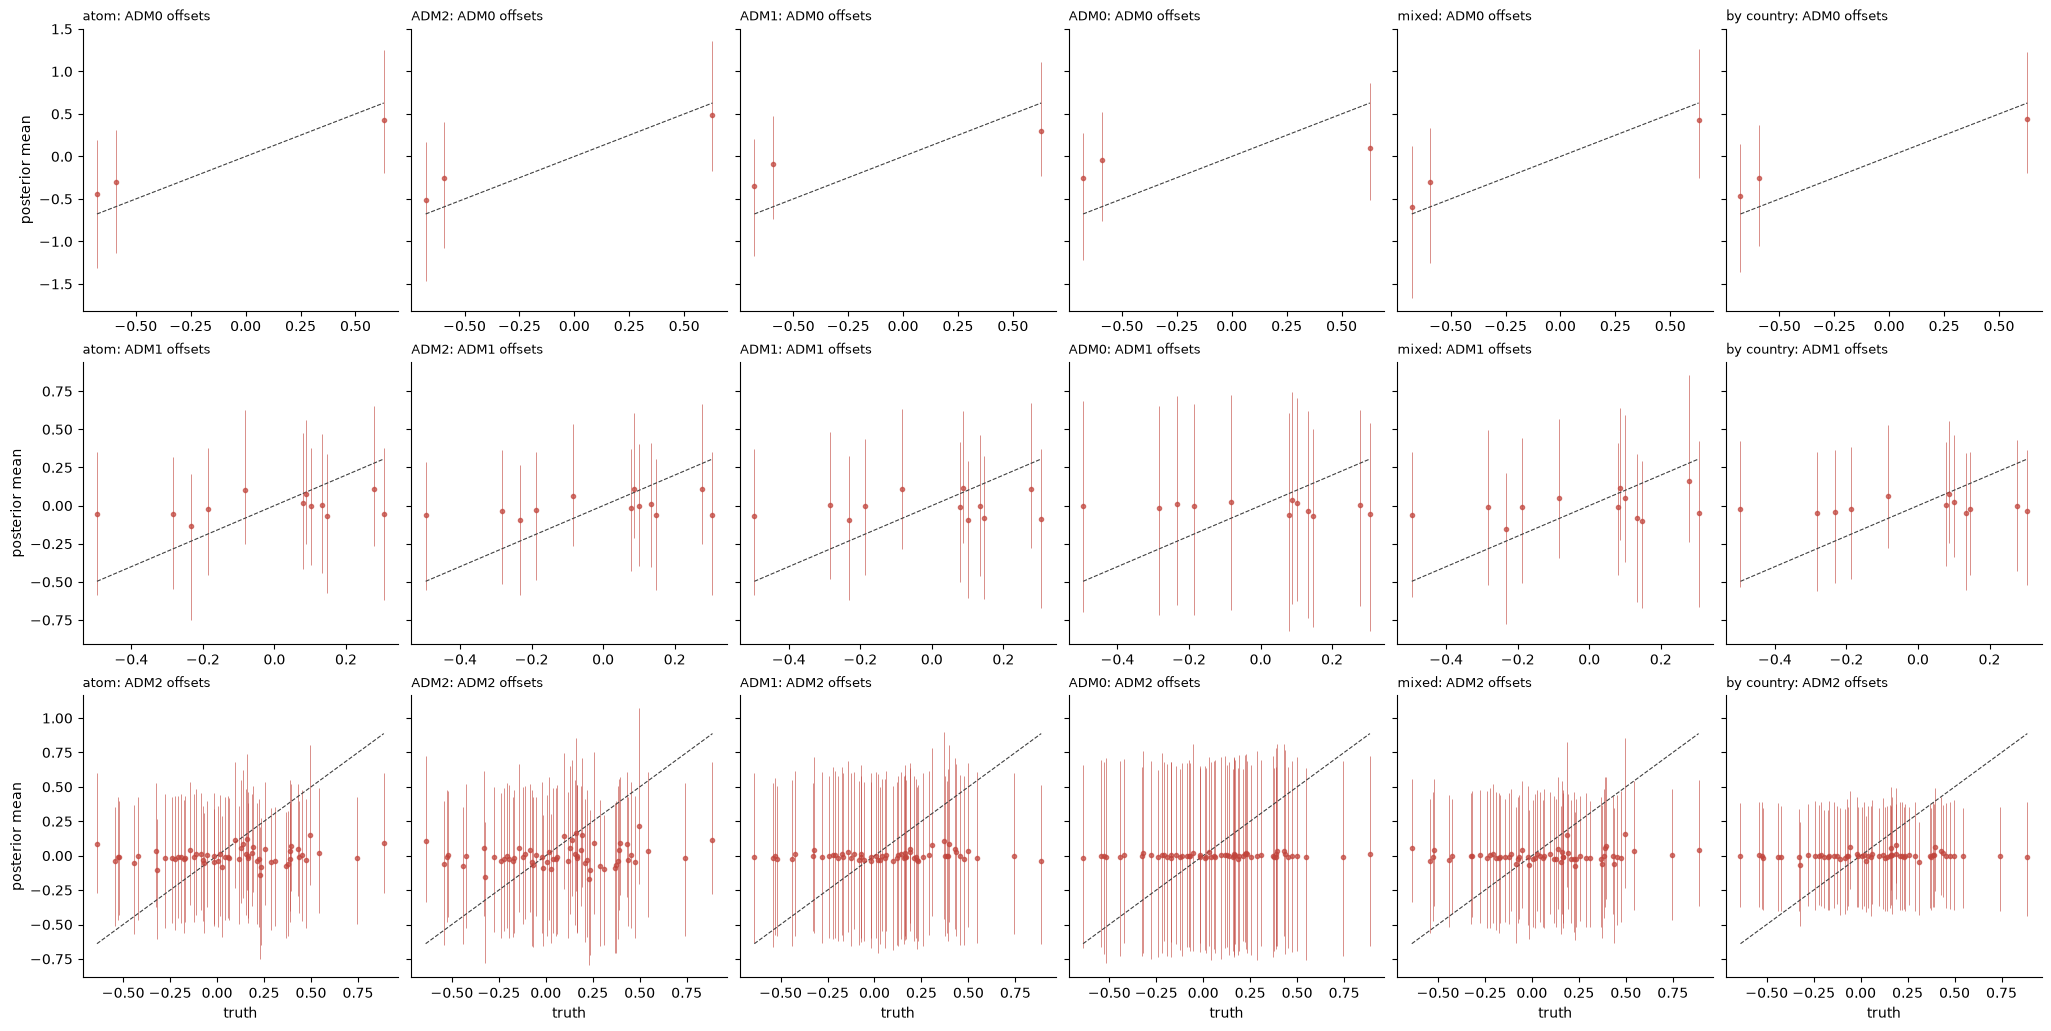

In [22]:
def plot_offset_recovery(fits):
    """Each unit's posterior mean offset and interval against its true value, one row per level."""
    figure, axes = plt.subplots(len(LEVELS),
                                len(fits),
                                figsize=(3.4 * len(fits), 3.4 * len(LEVELS)),
                                sharex="row",
                                sharey="row")

    for row, level in zip(axes, reversed(LEVELS), strict=True):
        truth = true_offsets[level]
        span = [truth.min(), truth.max()]
        for axis, (regime, idata) in zip(row, fits.items(), strict=True):
            draws = idata.posterior[f"{level}_offset"]
            mean = draws.mean(dim=("chain", "draw")).to_numpy()
            lower, upper = draws.quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
            axis.errorbar(truth,
                          mean,
                          yerr=[mean - lower, upper - mean],
                          fmt="o",
                          markersize=3,
                          elinewidth=0.6,
                          color=POSTERIOR_COLOR,
                          alpha=0.7)
            axis.plot(span,
                      span,
                      color=TRUTH_COLOR,
                      linewidth=0.8,
                      linestyle="--")
            axis.set_title(f"{regime}: {level} offsets", loc="left", fontsize=9)
        row[0].set_ylabel("posterior mean")

    for axis in axes[-1]:
        axis.set_xlabel("truth")

    plt.show()


plot_offset_recovery(fits)

Every record that reports below the country orders the countries correctly. The oracle, ADM2, mixed and per-country fits put ADM0 0 at 0.43 to 0.48 against its true +0.63, and the other two between -0.25 and -0.59. The ADM1 and ADM0 records shrink ADM0 0 further (0.30 and 0.10), since a country total cannot tell a country offset from the covariates and the field. Below the country, every regime shrinks the offsets toward zero, with intervals of about plus or minus 0.5 that widen to the prior's spread in the ADM1 and ADM0 fits. A simulated ADM2 unit holds 1.3 events on average, and a count that small cannot separate an offset with sd 0.3 from Poisson noise, so partial pooling returns each unit to its parent.

### What the record shows against what the fit infers

The top row is the record as a reader without a model would map it: each event spread evenly over the unit it was reported in, with records reported at more than one level drawn as a stack. The middle row is the posterior mean rate at each atom, and the bottom row is that mean against the truth. The first column is the truth itself and the residual of the oracle fit. The top two rows share one log scale in events per atom.

In [23]:
def spread_at(counts, level):
    """The events reported at ``level``, each divided equally among the atoms of its unit."""
    return spread_over_units(counts[rows_of[level]], unit_of_atom[level])


def spread_evenly(counts):
    """Each reported event divided equally among the atoms of the unit it was reported in."""
    return sum(spread_at(counts, level) for level in ALL_LEVELS)


def record_layers(counts):
    """A record as one sheet per reporting level, coarsest first, then their sum."""
    layers = [
        (f"{level}, {counts[rows_of[level]].sum()} events", spread_at(counts, level), (level,))
        for level in reversed(LEVELS)
    ]

    return [*layers, ("sum", spread_evenly(counts), LEVELS)]


def posterior_rate(idata):
    """Posterior mean of the expected events at each atom."""
    return np.exp(idata.posterior["log_rate"]).mean(dim=("chain", "draw")).to_numpy()

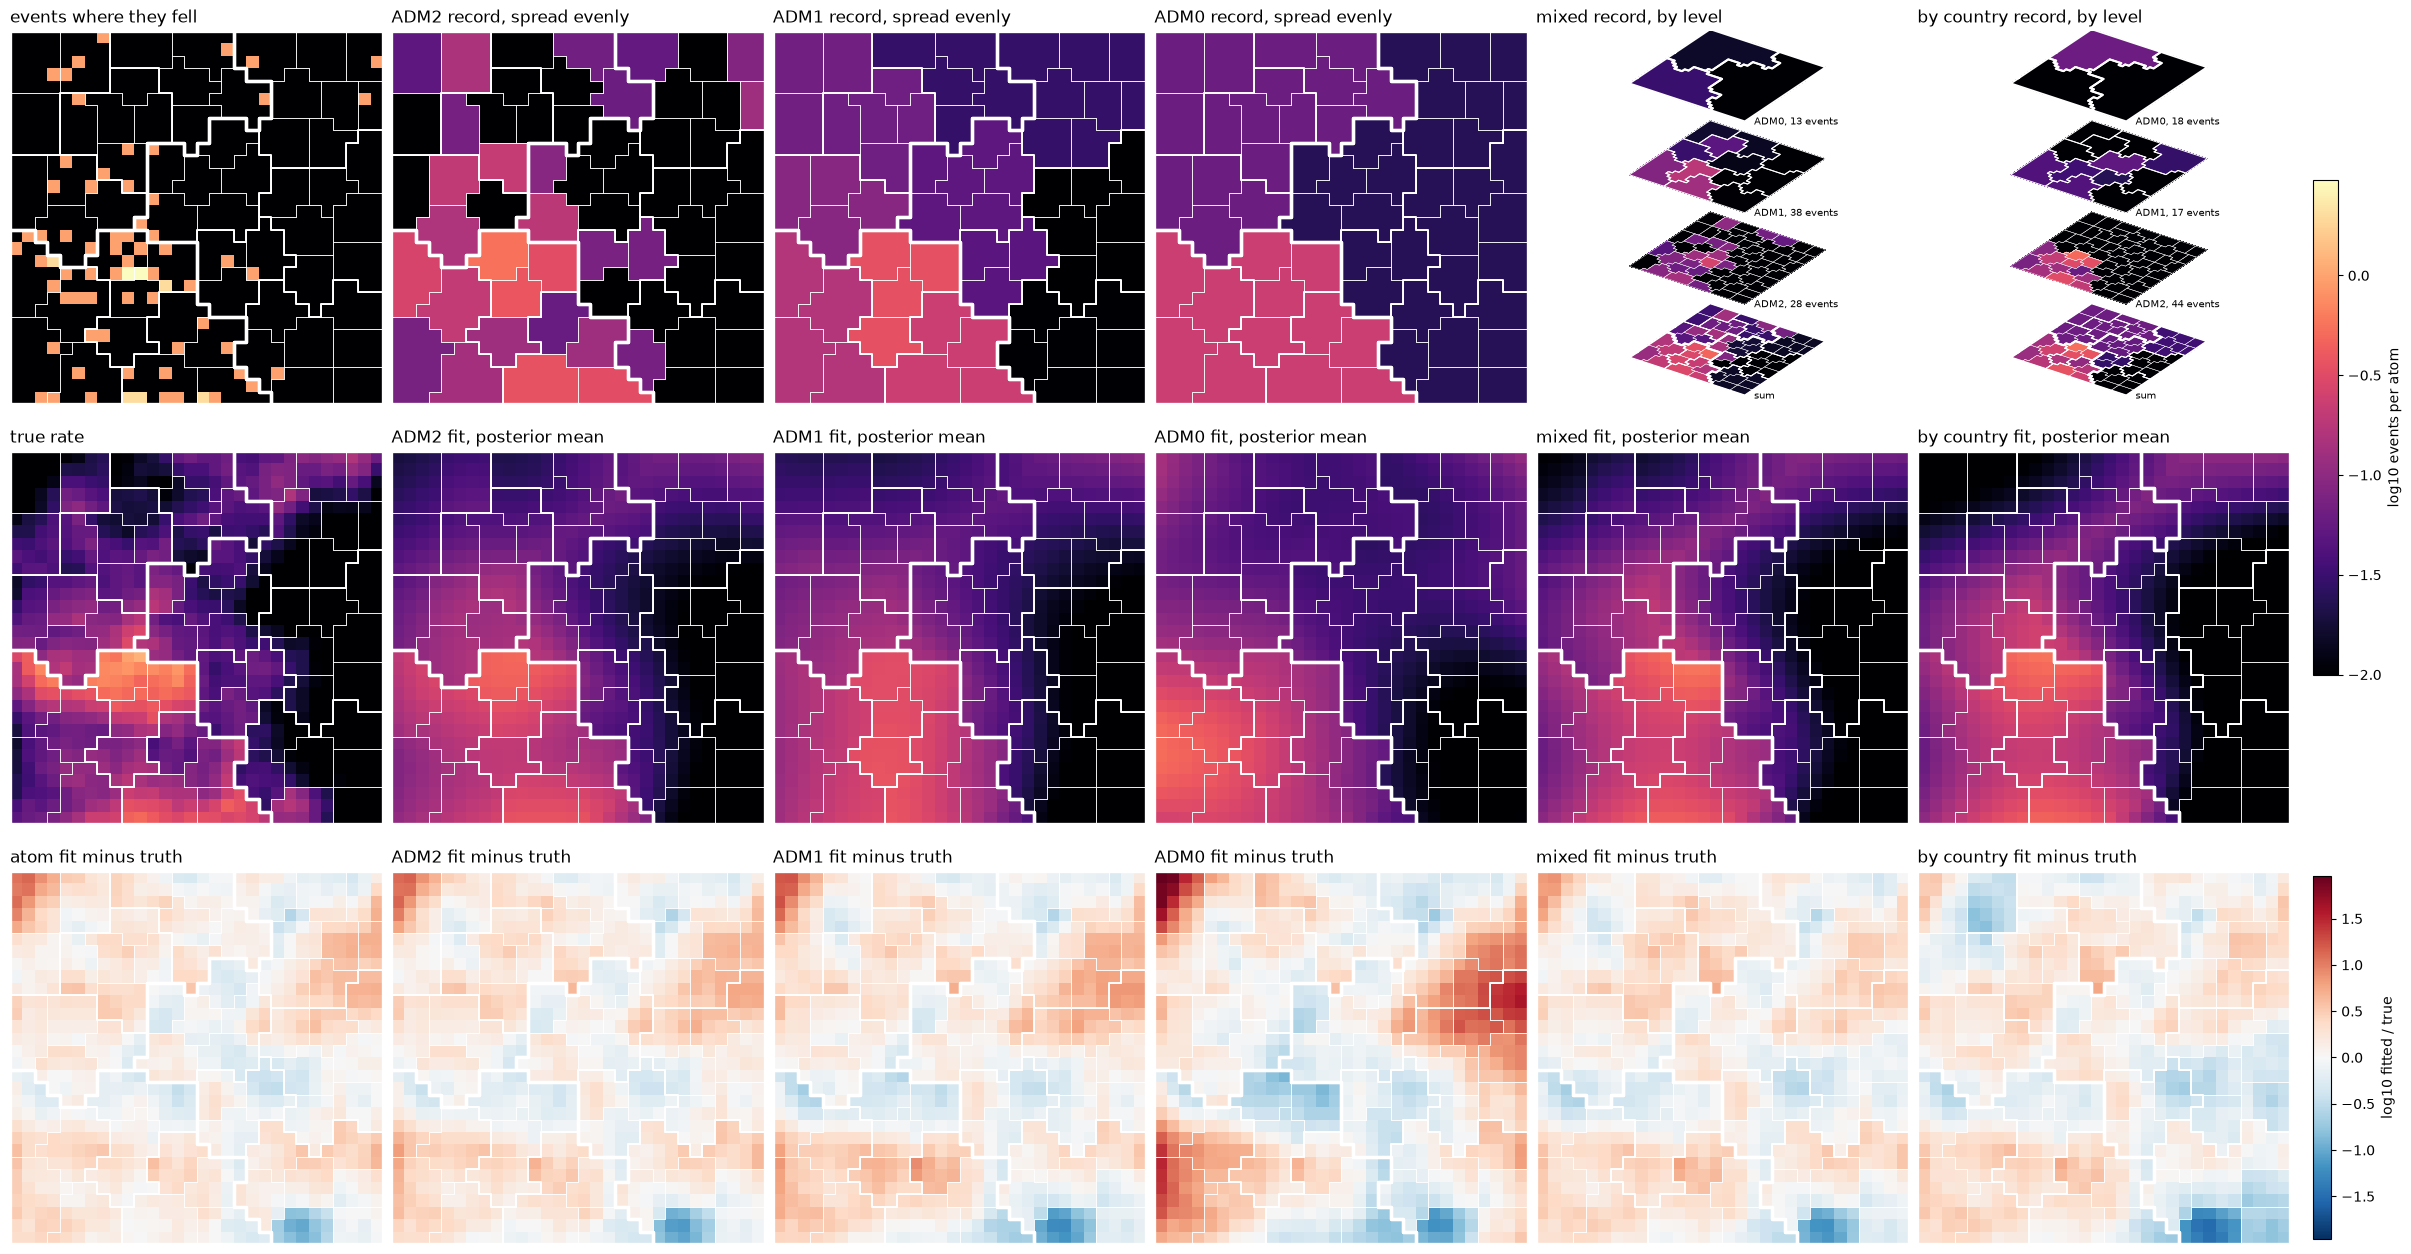

In [24]:
SHOWN_REGIMES = ("ADM2", "ADM1", "ADM0", "mixed", "by country")
STACKED_REGIMES = ("mixed", "by country")

columns = {"truth": (spread_evenly(regimes["atom"]), true_rate)}
columns |= {regime: (spread_evenly(regimes[regime]), posterior_rate(fits[regime])) for regime in SHOWN_REGIMES}

# The truth column has no fit of its own, so its residual is the oracle's: what the draw of events
# alone costs, before any reporting.
residuals = {
    name: np.log10(posterior_rate(fits["atom" if name == "truth" else name])) - np.log10(true_rate) for name in columns
}

low = np.log10(RATE_FLOOR)
high = np.log10(max(values.max() for pair in columns.values() for values in pair))
residual_limit = max(np.abs(residual).max() for residual in residuals.values())

figure, axes = plt.subplots(3, len(columns), figsize=(4.0 * len(columns), 12.6))
rate_axes = list(axes[:2].ravel())

for (name, (seen, inferred)), (top, middle, bottom) in zip(columns.items(), axes.T, strict=True):
    inferred_title = "true rate" if name == "truth" else f"{name} fit, posterior mean"
    residual_title = "atom fit minus truth" if name == "truth" else f"{name} fit minus truth"

    if name in STACKED_REGIMES:
        rate_axes.remove(top)
        top.remove()
        stack = figure.add_subplot(top.get_subplotspec(), projection="3d", proj_type="ortho")
        draw_stack(stack,
                   record_layers(regimes[name]),
                   borders,
                   vmin=low,
                   vmax=high,
                   label_size=7,
                   zoom=1.1,
                   line_scale=0.6)
        stack.set_title(f"{name} record, by level", loc="left")
    else:
        seen_title = "events where they fell" if name == "truth" else f"{name} record, spread evenly"
        plot_atoms(top,
                   floored_log10(seen),
                   borders,
                   title=seen_title,
                   vmin=low,
                   vmax=high)

    rate_drawn = plot_atoms(middle,
                            floored_log10(inferred),
                            borders,
                            title=inferred_title,
                            vmin=low,
                            vmax=high)
    residual_drawn = plot_atoms(bottom,
                                residuals[name],
                                borders,
                                title=residual_title,
                                cmap="RdBu_r",
                                vmin=-residual_limit,
                                vmax=residual_limit)

figure.colorbar(rate_drawn,
                ax=rate_axes,
                shrink=0.6,
                pad=0.01,
                label="log10 events per atom")
figure.colorbar(residual_drawn,
                ax=axes[2],
                shrink=0.9,
                pad=0.01,
                label="log10 fitted / true")
plt.show()

In [25]:
pd.DataFrame(
    {
        "rmse": {name: float(np.sqrt((residual**2).mean())) for name, residual in residuals.items()},
        "largest": {name: float(np.abs(residual).max()) for name, residual in residuals.items()},
    }
).rename(index={"truth": "atom"}).rename_axis("log10 residual").round(3)

,rmse,largest
log10 residual,,
atom,0.30,1.13
ADM2,0.32,1.16
ADM1,0.37,1.25
ADM0,0.53,1.96
mixed,0.31,1.19
by country,0.34,1.51


The record maps carry the country step plainly: ADM0 0, with 53 of the 79 events, is bright in every record. The fits rebuild the step and the broad southwestern hotspot in every regime, the ADM0 fit most weakly. Every fit misses the same features in the residual row, overestimating the northeast and missing the low pocket on the southern edge. The residual root mean square is 0.30 to 0.37 in log10 for every regime except ADM0 (0.53), whose largest miss reaches 1.96, a factor of about 90.

### Each part of the log rate against the truth

The level, each covariate term, the summed unit offsets and the field, posterior mean against the truth at every atom. The offsets and the field are each centered, since only their shape is identified apart from the intercept, and their means are folded into the level.

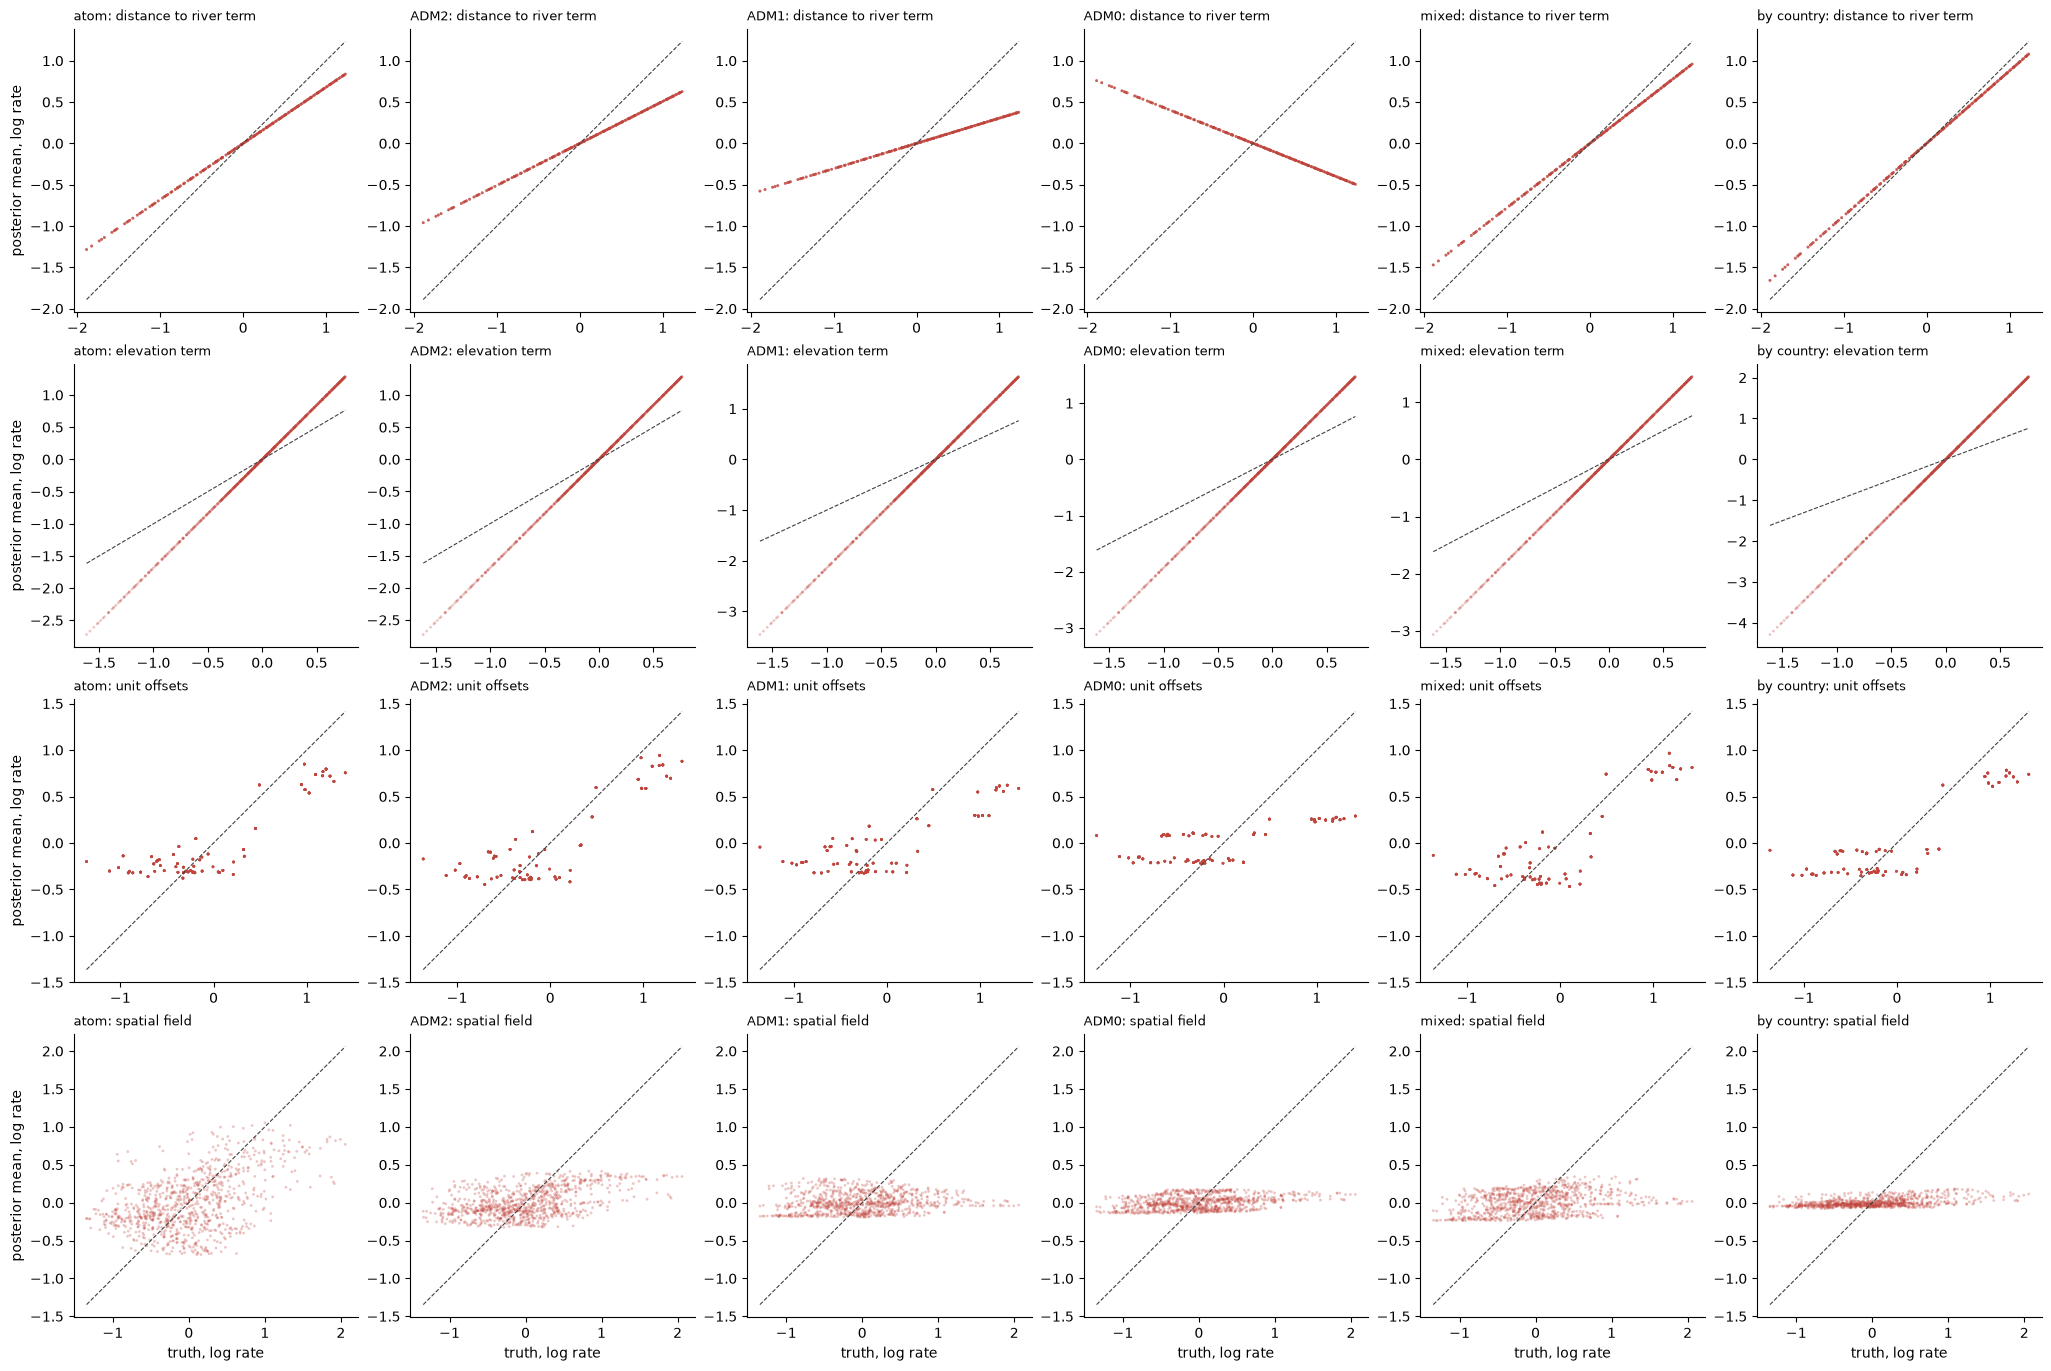

In [26]:
def covariate_terms_of(slopes):
    """Each covariate's contribution to the log rate at every atom."""
    return {
        f"{name} term": slope * values
        for name, slope, values in zip(COVARIATE_NAMES, slopes, covariates.T, strict=True)
    }


def offsets_at_atoms(posterior):
    """Draws of every atom's summed unit offsets, shape ``(chain, draw, atom)``."""
    return sum(posterior[f"{level}_offset"].to_numpy()[..., unit_of_atom[level]] for level in LEVELS)


def components_of(posterior):
    """Posterior mean of each additive part of the log rate at every atom, the offsets and field centered into the level."""
    field = posterior["field"].to_numpy()
    offsets = offsets_at_atoms(posterior)
    field_mean = field.mean(axis=-1, keepdims=True)
    offset_mean = offsets.mean(axis=-1, keepdims=True)

    return {
        "level": float((posterior["intercept"].to_numpy()[..., None] + field_mean + offset_mean).mean()),
        **covariate_terms_of(posterior["slopes"].mean(dim=("chain", "draw")).to_numpy()),
        "unit offsets": (offsets - offset_mean).mean(axis=(0, 1)),
        "spatial field": (field - field_mean).mean(axis=(0, 1)),
    }


true_components = {
    "level": TRUE_INTERCEPT + offset_part.mean(),
    **covariate_terms_of(TRUE_SLOPES),
    "unit offsets": offset_part - offset_part.mean(),
    "spatial field": true_field,
}
fitted_components = {regime: components_of(idata.posterior) for regime, idata in fits.items()}
spatial_components = [name for name in true_components if name != "level"]

figure, axes = plt.subplots(len(spatial_components),
                            len(fits),
                            figsize=(3.4 * len(fits), 3.4 * len(spatial_components)))

for row, name in zip(axes, spatial_components, strict=True):
    truth = true_components[name]
    span = [truth.min(), truth.max()]
    for axis, (regime, fitted) in zip(row, fitted_components.items(), strict=True):
        axis.scatter(truth,
                     fitted[name],
                     s=4,
                     alpha=0.3,
                     color=POSTERIOR_COLOR,
                     edgecolor="none")
        axis.plot(span,
                  span,
                  color=TRUTH_COLOR,
                  linewidth=0.8,
                  linestyle="--")
        axis.set_title(f"{regime}: {name}", loc="left", fontsize=9)
    row[0].set_ylabel("posterior mean, log rate")

for axis in axes[-1]:
    axis.set_xlabel("truth, log rate")

plt.show()

In [27]:
pd.DataFrame(
    {
        regime: {
            "level, error": fitted["level"] - true_components["level"],
            **{
                f"{name}, rmse": float(np.sqrt(((fitted[name] - true_components[name]) ** 2).mean()))
                for name in spatial_components
            },
        }
        for regime, fitted in fitted_components.items()
    }
).round(3)

,atom,ADM2,ADM1,ADM0,mixed,by country
"level, error",0.03,0.11,0.04,-0.22,-0.02,-0.19
"distance to river term, rmse",0.26,0.39,0.56,1.12,0.18,0.10
"elevation term, rmse",0.34,0.34,0.57,0.47,0.45,0.83
"unit offsets, rmse",0.41,0.40,0.50,0.60,0.40,0.42
"spatial field, rmse",0.55,0.55,0.61,0.59,0.59,0.59


The offsets row shows the shrinkage from another angle. In the oracle, ADM2, mixed and per-country fits the fitted offsets split into a high cluster for ADM0 0 and a low one for the rest, with little order inside either, so only the country step survives. In the ADM1 fit the step shrinks, and in the ADM0 fit the clusters flatten into bands. The field row is compressed toward zero in every regime and nearly flat in ADM1 and ADM0, with rmse 0.55 to 0.61 everywhere. The level is within 0.22 of the truth everywhere. The elevation term is too steep in every fit, worst in the per-country fit (rmse 0.83), and ADM0's river term carries its wrong-signed slope (rmse 1.12).

### The fitted field as a map

The true field beside each regime's posterior-mean field, on one color scale. Each fitted field is centered, since the intercept absorbs its mean.

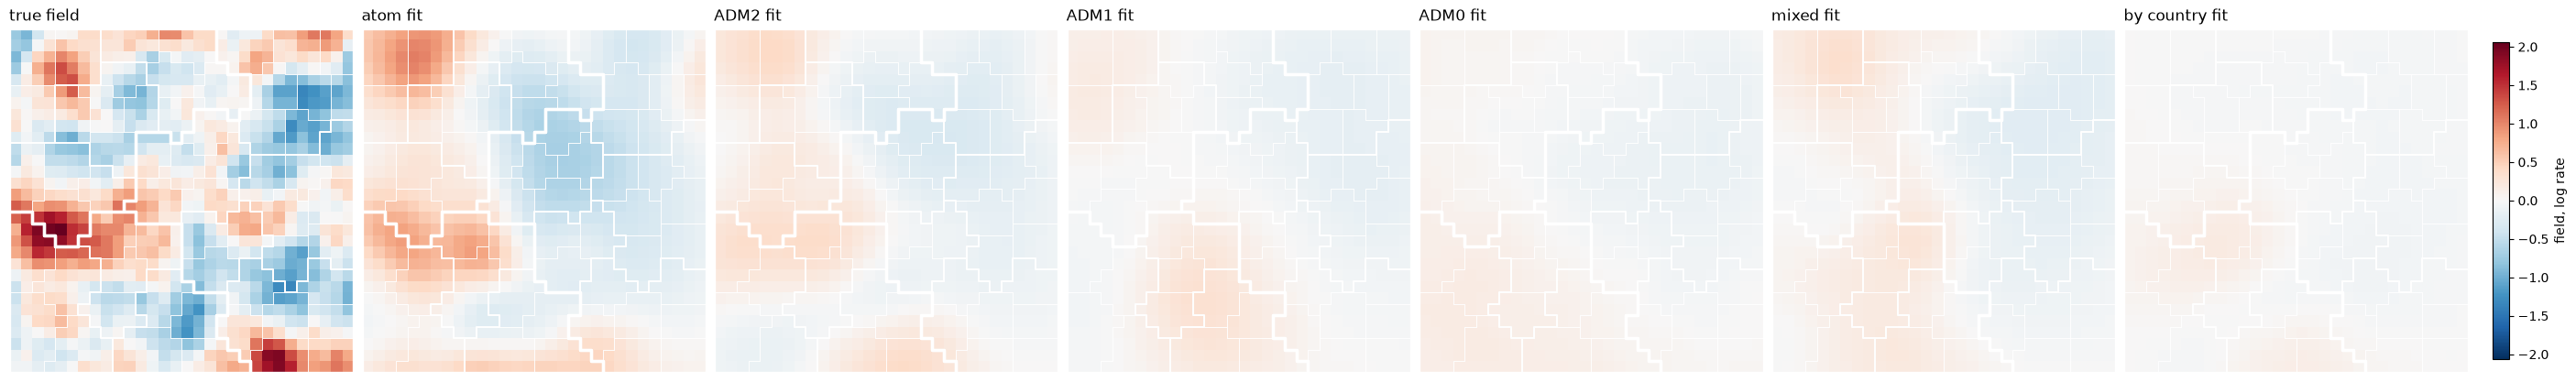

In [37]:
def centered_field(idata):
    """The posterior-mean field with its mean removed."""
    field = posterior_mean(idata.posterior, "field")

    return field - field.mean()


plot_fields({"true field": true_field} | {f"{regime} fit": centered_field(idata) for regime, idata in fits.items()},
            borders)
plt.show()

Only the oracle draws a recognizable field: the western hotspot, a warm patch in the northwest and a cold region east of center, all smoother and paler than the truth. The southern hotspot is missing. The ADM2 and mixed fits keep a faint version of the same west-to-east gradient, and the ADM1, ADM0 and per-country fits are nearly flat. 06's ADM2 and mixed fits found three features, but from 163 events against 79 here, so the map does not separate the cost of the offsets from the cost of fewer events.

### Field recovery inside units

The fitted field against the truth after removing each unit's own mean, so only structure below the unit counts. The offsets are constant inside their units and drop out. Rows split by the level of the unit and by country, each country labeled by how it reports in the per-country regime.

In [28]:
INSIDE_LEVELS = ("ADM2", "ADM1")

country_of_atom = unit_of_atom["ADM0"]
habits = [", ".join(f"{level} {share:.0%}" for level, share in shares.items()) for shares in COUNTRY_SHARES]
field_means = {regime: idata.posterior["field"].mean(dim=("chain", "draw")).to_numpy() for regime, idata in fits.items()}


def unit_mean_at_atoms(values, units):
    """Each atom's value replaced by the mean over the unit it sits in."""
    return (np.bincount(units, weights=values) / np.bincount(units))[units]


def inside_recovery(field_mean, level, atoms):
    """Correlation of the fitted field with the truth after removing each unit's mean, over ``atoms``."""
    fitted = field_mean - unit_mean_at_atoms(field_mean, unit_of_atom[level])
    truth = true_field - unit_mean_at_atoms(true_field, unit_of_atom[level])

    return correlation(fitted[atoms], truth[atoms])


groups = {"all countries": np.ones(n_atoms, dtype=bool)}
groups |= {f"ADM0 {country} ({habit})": country_of_atom == country for country, habit in enumerate(habits)}

pd.DataFrame(
    {
        regime: {
            (f"inside {level} units", group): inside_recovery(field_mean, level, atoms)
            for level in INSIDE_LEVELS
            for group, atoms in groups.items()
        }
        for regime, field_mean in field_means.items()
    }
).rename_axis(["field, correlation with truth", "over"]).round(3)

atom  ADM2  ADM1  \
field, correlation with truth over                                            
inside ADM2 units             all countries                0.43  0.32 -0.02   
                              ADM0 0 (ADM2 80%, ADM1 20%)  0.61  0.33 -0.28   
                              ADM0 1 (ADM1 80%, ADM0 20%)  0.08  0.20  0.10   
                              ADM0 2 (ADM0 100%)           0.58  0.44  0.19   
inside ADM1 units             all countries                0.50  0.47 -0.03   
                              ADM0 0 (ADM2 80%, ADM1 20%)  0.76  0.68 -0.40   
                              ADM0 1 (ADM1 80%, ADM0 20%)  0.26  0.33  0.12   
                              ADM0 2 (ADM0 100%)           0.59  0.48  0.12   

                                                           ADM0  mixed  \
field, correlation with truth over                                       
inside ADM2 units             all countries                0.10   0.16   
                              ADM0 0 (ADM2 80%, ADM1 20%) -0.12  -0.00   
                              ADM0 1 (ADM1 80%, ADM0 20%)  0.19   0.07   
                              ADM0 2 (ADM0 100%)           0.19   0.35   
inside ADM1 units             all countries                0.24   0.24   
                              ADM0 0 (ADM2 80%, ADM1 20%) -0.20   0.05   
                              ADM0 1 (ADM1 80%, ADM0 20%)  0.40   0.28   
                              ADM0 2 (ADM0 100%)           0.36   0.31   

                                                           by country  
field, correlation with truth over                                     
inside ADM2 units             all countries                      0.22  
                              ADM0 0 (ADM2 80%, ADM1 20%)        0.23  
                              ADM0 1 (ADM1 80%, ADM0 20%)        0.22  
                              ADM0 2 (ADM0 100%)                 0.28  
inside ADM1 units             all countries                      0.44  
                              ADM0 0 (ADM2 80%, ADM1 20%)        0.59  
                              ADM0 1 (ADM1 80%, ADM0 20%)        0.42  
                              ADM0 2 (ADM0 100%)                 0.43

Field recovery inside units follows the field correlation. Over all countries and inside ADM1 units, the oracle, ADM2 and per-country fits reach 0.44 to 0.50, mixed and ADM0 0.24, and ADM1 -0.03. The noise floor inside a single country is wide: with no information inside any country, the all-ADM0 fit's correlations inside ADM1 units range from -0.20 to 0.40. Against that floor the ADM0-only country shows no gain from its neighbors (0.43 in the per-country fit against 0.36 when every country reports at ADM0).

## What this establishes

At the median country's 25 events, nested offsets below the country are not recoverable from any record, exact locations included. The ADM1 and ADM2 offset sds stay at their prior, the unit offsets shrink toward zero, and their correlation with the truth is at best 0.41 for ADM1 and 0.20 for ADM2. A simulated ADM2 unit holds 1.3 events on average, so its count cannot separate a 0.3 offset from Poisson noise. Every record orders the three countries correctly, and a record reported only at ADM0 or ADM1 shrinks the high-hazard country toward the others.

The field is limited by the same event count. A basis that covers the whole lengthscale prior leaves the oracle's field correlation at 0.47, against 0.48 under the smaller basis of 06, because the truth's lengthscale of 0.12 was already in the range the smaller basis approximated well. Every lengthscale posterior sits at the prior mean. The elevation slope is steep in every fit, 0.84 to 1.33 against a true 0.5, a candidate for confounding between elevation and the offsets that a correlation of elevation's unit means with the true offsets would check. At EM-DAT event counts, unit offsets below ADM0 need more events, by pooling hazards or years, or informative priors on their sds. This is one draw of events, field and offsets.

## Ten times the events

Two limits can hold the offsets back. Too few units leaves a level's sd unidentified however well each unit is measured, which caps ADM0 at three. Too few events per unit buries each offset in Poisson noise. Scaling the rate tenfold at fixed geography, field and offsets separates them: if the offsets and their sd come back, events per unit was the limit, and if the ADM0 sd stays at its prior, the unit count is. Ten times the median country is beyond what the record holds for almost every country, so this section shows the mechanism, not a regime the model will meet.

In [29]:
SCALE = 10

scaled_rate = true_rate * SCALE
scaled_event_atoms = np.repeat(np.arange(n_atoms), np.random.default_rng(EVENT_SEED).poisson(scaled_rate))
scaled_regimes = draw_regimes(scaled_event_atoms, np.random.default_rng(REPORTING_SEED))

pd.DataFrame(
    {regime: {level: counts[rows_of[level]].sum() for level in ALL_LEVELS} for regime, counts in scaled_regimes.items()}
).rename_axis("events reported at")

,atom,ADM2,ADM1,ADM0,mixed,by country
events reported at,,,,,,
atom,723,0,0,0,0,0
ADM2,0,723,0,0,298,388
ADM1,0,0,723,0,324,194
ADM0,0,0,0,723,101,141


In [30]:
scaled_fits = {}
for regime, counts in scaled_regimes.items():
    with build_model(counts):
        scaled_fits[regime] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


...

Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

In [31]:
def interval_width(draws):
    """Width of the central interval of one scalar variable's draws."""
    lower, upper = draws.quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()

    return float(upper - lower)


def offset_check(idata):
    """Offset recovery, offset sd posteriors, field recovery and sampler health for one fit."""
    posterior = idata.posterior

    return {
        **{
            f"{level} offsets, correlation with truth": correlation(posterior_mean(posterior, f"{level}_offset"),
                                                                    true_offsets[level])
            for level in reversed(LEVELS)
        },
        **{f"{level} offset sd, mean": float(posterior[f"{level}_offset_sd"].mean()) for level in reversed(LEVELS)},
        **{
            f"{level} offset sd, {INTERVAL:.0%} width": interval_width(posterior[f"{level}_offset_sd"])
            for level in reversed(LEVELS)
        },
        "field, correlation with truth": correlation(posterior_mean(posterior, "field"), true_field),
        "largest r_hat": float(az.summary(idata, var_names=CONVERGENCE_VARIABLES)["r_hat"].max()),
        "divergences": int(idata.sample_stats["diverging"].sum()),
    }


records = {f"{n_events} events": fits, f"{len(scaled_event_atoms)} events": scaled_fits}
checks = {
    label: pd.DataFrame({regime: offset_check(idata) for regime, idata in record_fits.items()})
    for label, record_fits in records.items()
}

pd.concat(checks, names=["record", "metric"]).swaplevel().loc[list(offset_check(fits["atom"]))].round(3)

atom  ADM2  ADM1  ADM0  \
metric                               record                               
ADM0 offsets, correlation with truth 79 events   1.00  0.98  0.94  0.82   
                                     723 events  1.00  1.00  1.00  0.99   
ADM1 offsets, correlation with truth 79 events   0.41  0.41  0.17 -0.30   
                                     723 events  0.50  0.32  0.04  0.06   
ADM2 offsets, correlation with truth 79 events   0.17  0.17  0.18  0.20   
                                     723 events  0.58  0.46  0.21  0.02   
ADM0 offset sd, mean                 79 events   0.53  0.57  0.43  0.38   
                                     723 events  0.78  0.67  0.53  0.33   
ADM1 offset sd, mean                 79 events   0.24  0.23  0.27  0.35   
                                     723 events  0.29  0.28  0.24  0.38   
ADM2 offset sd, mean                 79 events   0.23  0.27  0.31  0.35   
                                     723 events  0.19  0.30  0.34  0.38   
ADM0 offset sd, 90% width            79 events   0.99  1.03  0.90  0.92   
                                     723 events  0.82  0.82  0.96  0.77   
ADM1 offset sd, 90% width            79 events   0.59  0.58  0.60  0.82   
                                     723 events  0.56  0.55  0.52  0.88   
ADM2 offset sd, 90% width            79 events   0.55  0.59  0.71  0.82   
                                     723 events  0.38  0.56  0.72  0.83   
field, correlation with truth        79 events   0.47  0.46  0.11  0.32   
                                     723 events  0.76  0.70  0.13  0.21   
largest r_hat                        79 events   1.03  1.05  1.03  1.05   
                                     723 events  1.08  1.09  1.06  1.13   
divergences                          79 events   1.00  1.00  3.00 14.00   
                                     723 events  0.00  7.00  6.00 82.00   

                                                 mixed  by country  
metric                               record                         
ADM0 offsets, correlation with truth 79 events    0.97        0.98  
                                     723 events   1.00        1.00  
ADM1 offsets, correlation with truth 79 events    0.34        0.18  
                                     723 events   0.43        0.22  
ADM2 offsets, correlation with truth 79 events    0.12        0.17  
                                     723 events   0.36        0.18  
ADM0 offset sd, mean                 79 events    0.56        0.54  
                                     723 events   0.67        0.70  
ADM1 offset sd, mean                 79 events    0.26        0.23  
                                     723 events   0.26        0.35  
ADM2 offset sd, mean                 79 events    0.24        0.19  
                                     723 events   0.25        0.36  
ADM0 offset sd, 90% width            79 events    1.06        0.95  
                                     723 events   0.85        0.92  
ADM1 offset sd, 90% width            79 events    0.66        0.59  
                                     723 events   0.56        0.71  
ADM2 offset sd, 90% width            79 events    0.58        0.46  
                                     723 events   0.52        0.67  
field, correlation with truth        79 events    0.30        0.47  
                                     723 events   0.64        0.46  
largest r_hat                        79 events    1.05        1.02  
                                     723 events   1.07        1.06  
divergences                          79 events    7.00        0.00  
                                     723 events   8.00       11.00

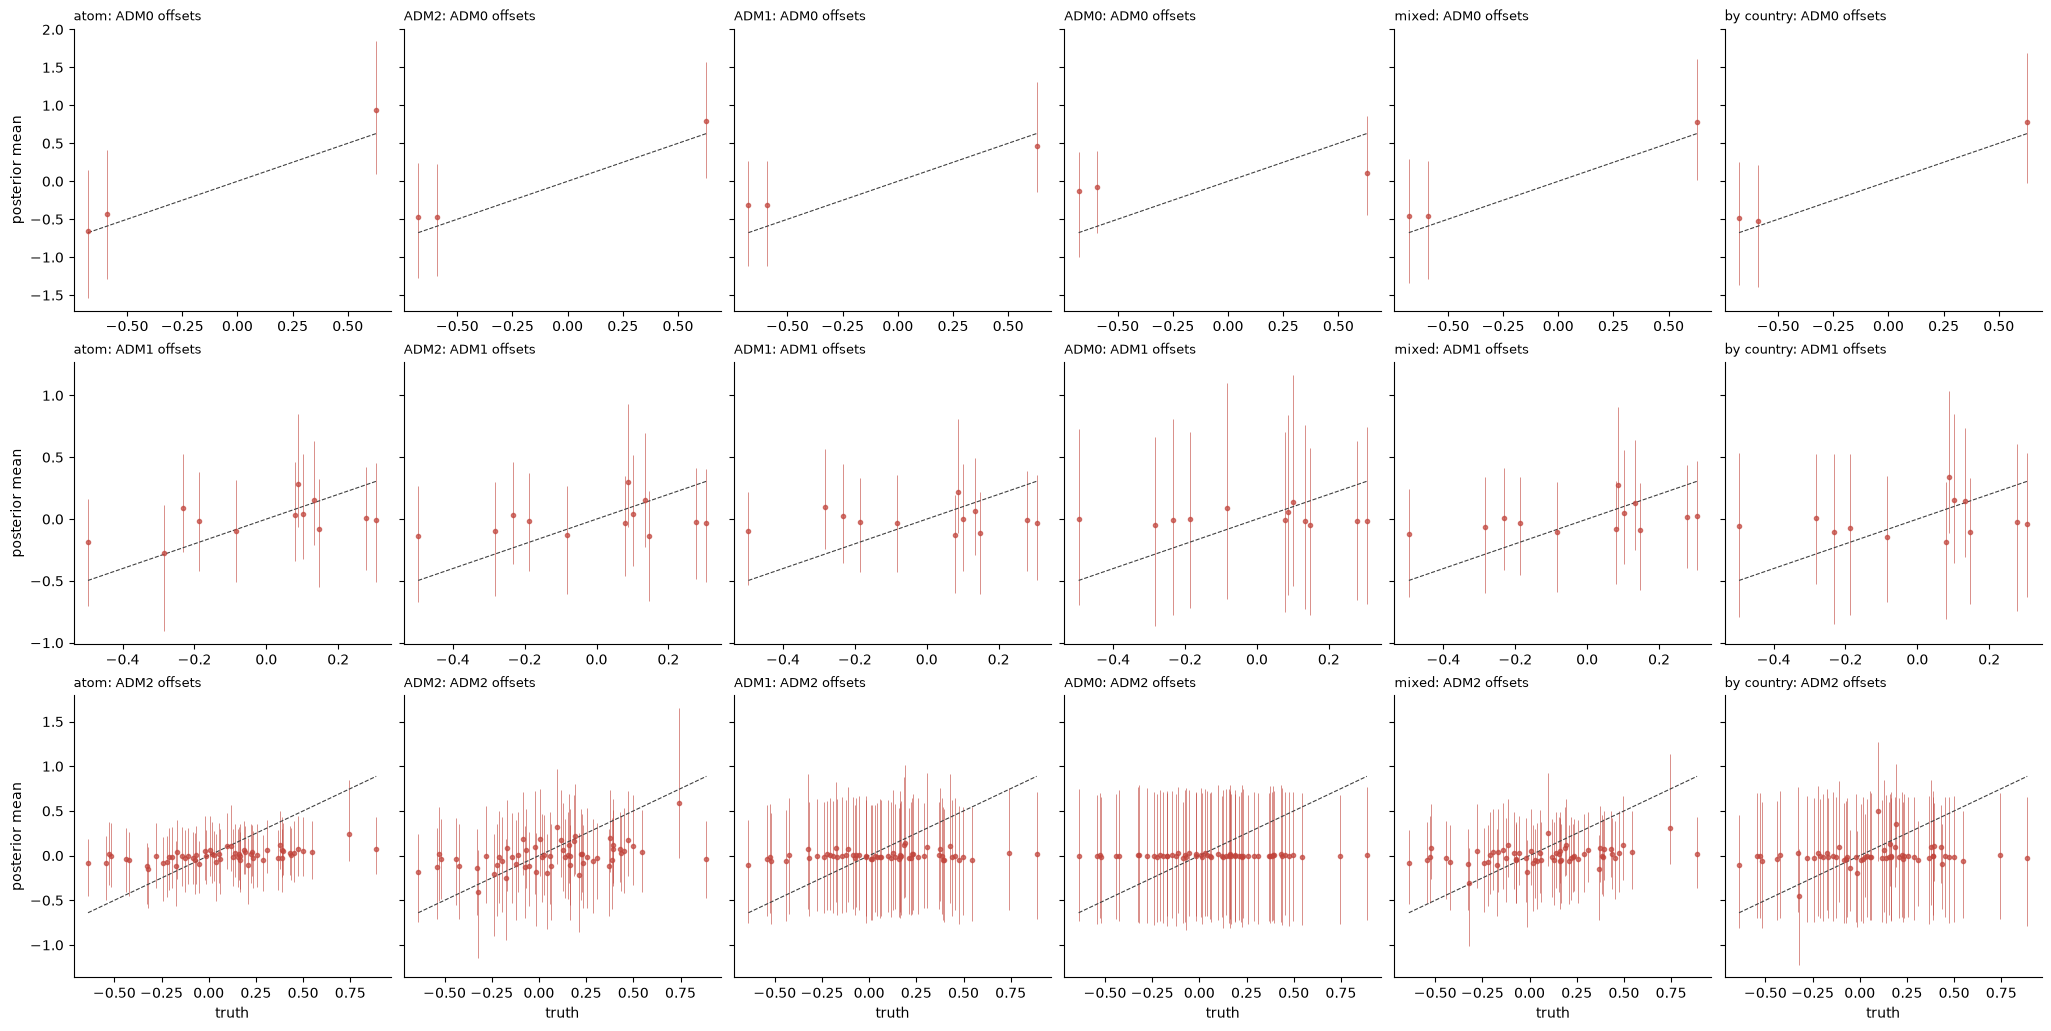

In [32]:
plot_offset_recovery(scaled_fits)

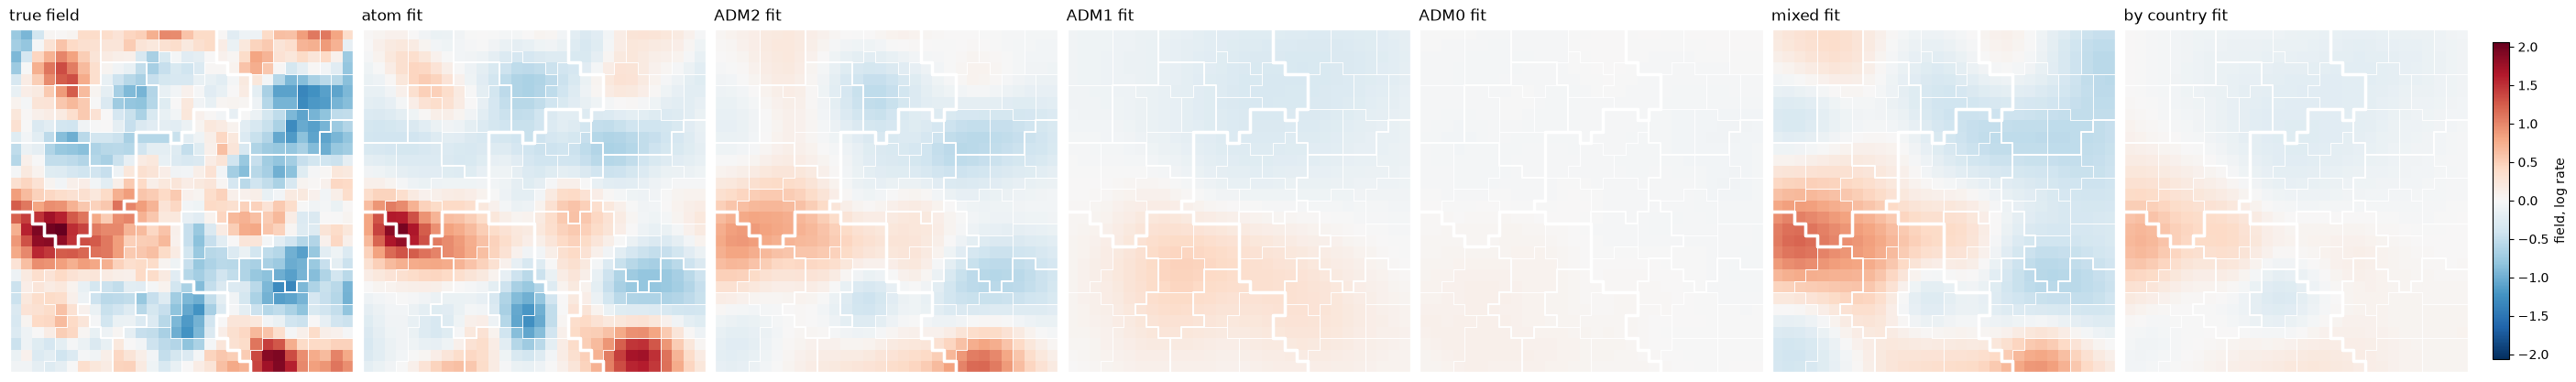

In [38]:
plot_fields({"true field": true_field} | {f"{regime} fit": centered_field(idata) for regime, idata in scaled_fits.items()},
            borders)
plt.show()

The two limits separate. At ADM2 the limit was events per unit. With 723 events, about 12 per ADM2 unit, the ADM2 offsets come back where the record resolves them: 0.58 from exact locations and 0.46 from ADM2 reports, against 0.17 for both at 79 events, and the oracle's ADM2 sd interval narrows from 0.55 to 0.38 wide. Records that never report below ADM1 stay near zero (0.21 and 0.02), and no event count changes that. A report coarser than a unit carries no information about the unit's offset. The mixed record reaches 0.36 and the per-country record 0.18, though the per-country record has more ADM2 reports: all of them fall in one country, so the ADM2 offsets of the other two stay at their prior.

At ADM0 the limit is the unit count. The three country offsets were already ordered at 79 events, and at 723 events the ADM0 sd's interval is still 0.77 to 0.96 wide in every regime. ADM1 sits between. Its offsets improve in the oracle and mixed fits (0.50 and 0.43), but its sd stays unidentified (widths 0.52 to 0.88) with twelve units. An ADM1-only record still does not recover the ADM1 offsets (0.04), though it reports exactly at that level: twelve unit totals cannot separate ADM1 steps from the field and covariates that also differ between ADM1 units.

The field gains with events only where the record resolves it. The oracle rises from 0.47 to 0.76, ADM2 from 0.46 to 0.70 and mixed from 0.30 to 0.64, while ADM1 and ADM0 stay at 0.13 and 0.21. On the map the oracle resolves both hotspots and the cold patches south and east of center. The ADM2 and mixed fits find the western and southern hotspots and the cold band across the north and east, the ADM1 fit only a warm south and a cool north, and the ADM0 fit nothing. The oracle's lengthscale posterior moves onto the truth (mean 0.12, 90% interval 0.08 to 0.18) and its amplitude to 0.73 against 0.7, so at this count exact locations identify the field's hyperparameters. The sampler struggles more as the data sharpen: r_hat reaches 1.13 and the ADM0 fit has 82 divergences, so the ADM0 numbers are provisional.